# Juice+: Finding the Extra Gear in the "Underwear Olympics"

Scouts say a player has **juice** when he has an extra gear the players around him don't: the receiver who runs past a corner who had him covered, the safety who closes on a ball that looked out of reach. It's the speed and explosiveness that **pops off the screen**.

The Combine is often mocked as the **"Underwear Olympics"**: prospects run and jump in shorts, with no pads, no opponent and no playbook, so many evaluators doubt the drills say much about football. We agree they don't tell you who can *play*. We ask a narrower question a front office can act on:

> **If a team wants to add juice to its roster, does the way a prospect moves in Combine drills show up in how he moves in NFL games?**

**Juice+** answers it with one number, built from the Combine's 10 Hz tracking and rebuilt the same way from NFL game tracking.

**Key findings (303 rookies with both scores, 2023–2025 classes):**
- **Combine juice shows up on Sundays.** An elite Combine Juice+ (110+) moved like an above-average athlete in games **69%** of the time (all players: 50%) and like an elite one **31%** of the time (17%). A low one (under 90) stayed below average **78%** of the time (50%).
- **Speed and the first step carry; the position drills don't.**
- **Juice+ adds to what teams already have.** On draft classes it never saw, it improves on stopwatch results and draft position, is fair to every body type, and works as a draft-board filter (e.g., Will Mallory, TE, pick 162).

## 1. What Juice+ measures

Juice+ borrows from baseball's **OPS+**: compare a player with his peers, remove context that isn't ability, and report one number where **100 is average**. Here the peers are players at the same position, the context removed is **body size and draft class**, and **every 10 points is one standard deviation** (110 = one standard deviation better than the average player at his position).

It has three pieces, each measured with the same tracking instrument at the Combine and in games:

| Piece | Combine Juice+ (tracking) | Game Juice+ | Stopwatch tests averaged in |
|---|---|---|---|
| **Top-end speed** (the extra gear) | Fastest 10-yard stretch of the 40 | 95th percentile of peak speed per play | 40 time |
| **Explosiveness** (first step) | Yards covered in first 1.5 s; speed at 1.0 s | Best efforts of the same two measures after the snap | 10-yard split, vertical, broad jump |
| **Agility** (change of direction) | Pace and braking through position drills | Peak lateral acceleration | 3-cone, shuttle |

The bet: measuring *the same movement* on both sides adds to stopwatch scores like RAS and the NGS Athleticism Score, whose tests never happen on a snap.

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import animation
from scipy.stats import spearmanr
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from IPython.display import display, Image
warnings.filterwarnings("ignore")

DATA, CACHE = "/Users/ramsay_5/Desktop/NFL Big Data Bowl 2027/nfl-big-data-bowl-2027/", "juice_cache"
if os.path.isdir("/kaggle/input"):
    hits = glob.glob("/kaggle/input/**/players.csv", recursive=True)
    if hits:
        DATA = os.path.dirname(hits[0]) + "/"
    CACHE = "/kaggle/working/juice_cache"
os.makedirs(CACHE, exist_ok=True)
rng = np.random.default_rng(0)

# Settings
ROUTE_ADJ, LENGTH_ADJ, GAME_CLASS_ADJ = True, True, True
MIN_PLAY_SECONDS = 3.0; MIN_FRAMES = int(round(MIN_PLAY_SECONDS * 10))
GAME_MIN_BURST, GAME_MIN_PLAYS = 5, 20          # floors only; low-snap players are shrunk toward average instead
BLOWOUT_MARGIN, BLOWOUT_WP = 21, 0.05            # snaps dropped as blowouts (score margin, or win probability)
MIN_BURST_SEASON, MIN_PLAYS_SEASON = 30, 100
HIGH_PICK, LOW_PICK = 64, 140
HIGH_JUICE, LOW_JUICE = 110, 90
BELOW_AVG, ELITE = 100, 110
YD_TO_MPH = 3600 / 1760

# Position groups (linebackers and running backs have too few players to score)
PGM = {"T": "OL", "G": "OL", "C": "OL", "DT": "DL", "NT": "DL", "DE": "EDGE", "OLB": "EDGE",
       "CB": "DB", "DB": "DB", "SS": "DB", "FS": "DB", "WR": "WR", "TE": "TE"}
ALIAS = {"PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL", "SPEED_OUT_LEFT": "SPEED_OUT_ROUTE_LEFT",
         "OVER_THE_SHOULDER_ADJUST": "OVER_SHOULDER_ADJUST"}   # drills recorded under two spellings

# Accessible, colour-blind-safe palette (Okabe-Ito) and readable defaults
OI = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
GROUP_COL = dict(zip(["DB", "DL", "EDGE", "OL", "TE", "WR"], OI))
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

def fisher_ci(r, n):
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
def zs(s):
    return (s - s.mean()) / s.std()
def sb(k, r):  # Spearman-Brown: reliability of the mean of k measurements
    k = np.asarray(k, dtype=float)
    return np.clip(k * r / (1 + (k - 1) * r), 0, 1)
def scale100(df, col, by="pgm"):
    g = df.groupby(by)[col]
    return 100 + 10 * (df[col] - g.transform("mean")) / g.transform("std")
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p_ = k / n; den = 1 + z ** 2 / n
    ctr = (p_ + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p_ * (1 - p_) / n + z ** 2 / (4 * n ** 2)) / den
    return ctr - half, ctr + half

## 2. Building Juice+

**Data.** Every 2023–2025 rookie with Combine tracking in six position groups: 420 players.

1. **Top-end speed and explosiveness** come from the tracked 40, the one drill with the same layout for everyone. Top-end speed repeats almost perfectly between a player's two attempts (reliability 0.91); explosiveness is noisy (0.42).
2. **Agility** is mean speed and 95th-percentile acceleration through each position's drills. It counts only where a group's drills agree with each other (reliability ≥ 0.5): DL, OL, DB and WR pass; EDGE and TE don't, so their Juice+ is speed and explosiveness only.
3. **Size and class are removed.** Within each group, a leave-one-out ridge regression predicts each piece from weight, weight², height and draft class; Juice+ keeps what's left over. A 330-pound guard who moves like a 300-pound guard grades out *positive*.
4. **Noisy pieces are shrunk toward average** by their reliability.
5. **Each tracked piece is averaged with the stopwatch tests of the same trait** (table above), since two imperfect measures of one trait cancel some noise. The pieces are averaged and rescaled to 100 ± 10.

Without step 3, tracked speed is largely a scale reading. Among defensive linemen, weight and raw top-end speed have a rank correlation of −0.70; after adjustment it is −0.09 (Figure 1).

In [2]:
# ---------- Combine Juice+ pipeline (no output) ----------
players = pd.read_csv(DATA + "players.csv")
combine = pd.read_csv(DATA + "combine_results.csv")
LOWER_BETTER = ["forty", "ten_yd_split", "three_cone", "short_shuttle"]
HIGHER_BETTER = ["vertical", "broad_jump", "bench_reps"]
TESTS = combine[["nfl_id"] + [c for c in LOWER_BETTER + HIGHER_BETTER if c in combine.columns]].copy()
games = pd.read_csv(DATA + "games.csv")

D = players[["nfl_id", "display_name", "nfl_position", "draft_year", "draft_round", "draft_overall_pick"]].copy()
D["pgm"] = D.nfl_position.map(PGM)
D = D.dropna(subset=["pgm"]).merge(
    combine[["nfl_id", "combine_weight", "combine_height", "ngs_athleticism_score"]], on="nfl_id", how="left")

ct = pd.read_csv(DATA + "combine_tracking.csv",
                 usecols=["nfl_id", "entity_type", "event_id", "drill_name", "drill_type", "time", "x", "y", "s", "a"])
ct = ct[(ct.entity_type == "PLAYER") & ct.nfl_id.notna()].copy()
ct["nfl_id"] = ct.nfl_id.astype(int)
ct = ct[ct.nfl_id.isin(D.nfl_id)]
D = D[D.nfl_id.isin(set(ct.nfl_id))].copy()        # score only players with Combine tracking
ct["drill_name"] = ct.drill_name.replace(ALIAS)
ct["time"] = pd.to_datetime(ct.time)
ct = ct.sort_values(["event_id", "time"])
ct["t"] = (ct.time - ct.groupby("event_id").time.transform("min")).dt.total_seconds()

def feats40(a):
    s, x, t = a.s.values, a.x.values, a.t.values
    on = np.where(s >= 1.0)[0]
    if len(on) < 10:
        return None
    i0 = on[0]
    s, x, t = s[i0:], x[i0:], t[i0:]
    prog = np.maximum.accumulate(np.abs(x - x[0])) + np.arange(len(x)) * 1e-9
    if prog[-1] < 36:
        return None
    tt = t - t[0]
    best = 0.0
    for d in np.arange(5.0, min(prog[-1] - 10, 30.0) + 1e-6, 2.5):
        m = (prog >= d) & (prog <= d + 10)
        if m.sum() >= 5:
            best = max(best, s[m].mean())
    smooth = pd.Series(s).rolling(3, center=True, min_periods=1).mean().values
    return pd.Series({"d15": np.interp(1.5, tt, prog), "v1": np.interp(1.0, tt, smooth),
                      "fly10": best if best > 0 else np.nan})

f40 = ct[ct.drill_name == "FORTY_YARD_DASH"]
a40 = f40.groupby("event_id").apply(feats40).dropna(subset=["fly10"])
a40["nfl_id"] = f40.groupby("event_id").nfl_id.first().reindex(a40.index).astype(int)
a40 = a40.sort_index()
a40["k"] = a40.groupby("nfl_id").cumcount()

# Attempt-to-attempt reliability within position, after removing class means
w2 = a40[a40.k < 2].pivot(index="nfl_id", columns="k", values=["d15", "v1", "fly10"]).dropna()
w2.columns = [f"{f}_{k}" for f, k in w2.columns]
w2 = w2.reset_index().merge(D[["nfl_id", "pgm", "draft_year"]], on="nfl_id")
RELI = {}
for f in ["d15", "v1", "fly10"]:
    zsum, wsum = 0.0, 0.0
    for g, d in w2.groupby("pgm"):
        if len(d) < 15:
            continue
        x0 = d[f + "_0"] - d.groupby("draft_year")[f + "_0"].transform("mean")
        x1 = d[f + "_1"] - d.groupby("draft_year")[f + "_1"].transform("mean")
        zsum += np.arctanh(spearmanr(x0, x1)[0]) * (len(d) - 3); wsum += len(d) - 3
    RELI[f] = float(np.tanh(zsum / wsum)) if wsum > 0 else 0.6
REL_E, REL_T = (RELI["d15"] + RELI["v1"]) / 2, RELI["fly10"]
P40 = a40.groupby("nfl_id").agg(d15=("d15", "mean"), v1=("v1", "mean"), fly10=("fly10", "mean"),
                                attempts=("fly10", "size")).reset_index()

# Agility from the position drills
def drill_feats(a):
    s, t, acc = a.s.values, a.t.values, a.a.values
    on = np.where(s >= 1.0)[0]
    if len(on) < 10:
        return None
    i0, i1 = on[0], on[-1]
    if t[i1] - t[i0] < 1.0:
        return None
    return pd.Series({"mean_s": np.nanmean(s[i0:i1 + 1]), "acc95": np.nanpercentile(acc[i0:i1 + 1], 95)})

od = ct[ct.drill_name != "FORTY_YARD_DASH"]
ad = od.groupby("event_id").apply(drill_feats).dropna(subset=["mean_s"])
ad = ad.join(od.groupby("event_id").agg(nfl_id=("nfl_id", "first"), drill_type=("drill_type", "first"),
                                        drill_name=("drill_name", "first")))

# Movement drills per group (catching drills such as the gauntlet and over-the-shoulder are excluded)
DL_SUBS = ["PASS_RUSH_DRILL", "FRONT_START_WAVE", "FOUR_BAG_AGILITY", "RUN_AND_CLUB", "BODY_CONTROL", "RUN_THE_HOOP"]
FAM = {"DL": ("SKILL_DRILLS_DL", DL_SUBS), "EDGE": ("SKILL_DRILLS_DL", DL_SUBS),
       "OL": ("SKILL_DRILLS_OL", ["PASS_RUSH_DROP", "PASS_PRO", "FIVE_YARD_WAVE", "OL_PULL", "SCREEN"]),
       "DB": ("SKILL_DRILLS_DB", ["BACK_PEDAL_AND_90", "BACK_PEDAL_AND_TRANSITION", "BOX_DRILL", "W_DRILL",
                                  "TERYL_AUSTIN", "LINE_DRILL"]),
       "WR": ("SKILL_DRILLS_WR", ["SLANT_ROUTE", "DAGGER_ROUTE", "CURL_ROUTE", "SLOT_STRIKE", "COMEBACK",
                                  "SLOT_SAIL", "POST_CORNER", "SPEED_OUT", "GO_ROUTE", "RED_ZONE"]),
       "TE": ("SKILL_DRILLS_TE", ["FLAT_ROUTE", "HOOK_ROUTE", "IN_ROUTE", "WHEEL_ROUTE", "CORNER_ROUTE"])}
COMMON = ["THREE_CONE_DRILL", "SHORT_SHUTTLE"]
GATE_ALPHA, MIN_PLAYERS_DRILL, MIN_OVERLAP = 0.5, 20, 15

gate, rbar, agil_parts, GATE_ROWS, WIDE = {}, {}, [], [], {}
for g, (dtype, subs) in FAM.items():
    ids = set(D.loc[D.pgm == g, "nfl_id"])
    keep = ((ad.drill_type == dtype) & ad.drill_name.apply(lambda n: any(s_ in n for s_ in subs))) \
           | ad.drill_name.isin(COMMON)
    sub = ad[keep & ad.nfl_id.isin(ids)]
    pdr = sub.groupby(["nfl_id", "drill_name"])[["mean_s", "acc95"]].mean().reset_index()
    cnt = pdr.groupby("drill_name").nfl_id.nunique()
    pdr = pdr[pdr.drill_name.isin(cnt[cnt >= MIN_PLAYERS_DRILL].index)].copy()
    if pdr.drill_name.nunique() < 2:
        gate[g], rbar[g] = False, np.nan
        continue
    for col in ["mean_s", "acc95"]:
        pdr[col + "_z"] = pdr.groupby("drill_name")[col].transform(zs)
    pdr["pace"] = pdr[["mean_s_z", "acc95_z"]].mean(axis=1)
    wide = pdr.pivot(index="nfl_id", columns="drill_name", values="pace")
    cors, cols = [], list(wide.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            both = wide[[cols[i], cols[j]]].dropna()
            if len(both) >= MIN_OVERLAP:
                cors.append(np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1])
    rb = float(np.mean(cors)) if cors else np.nan
    k = float(wide.notna().sum(axis=1).median())
    alpha = k * rb / (1 + (k - 1) * rb) if np.isfinite(rb) and k >= 2 else np.nan
    gate[g], rbar[g] = bool(np.isfinite(alpha) and alpha >= GATE_ALPHA), rb
    GATE_ROWS.append((g, len(cols), round(rb, 2), k, round(alpha, 2), gate[g])); WIDE[g] = wide
    nd = wide.notna().sum(axis=1)
    agil_parts.append(pd.DataFrame({"agil": wide.mean(axis=1).where(nd >= 2), "n_drills": nd}).reset_index())
AGL = pd.concat(agil_parts, ignore_index=True)

def adjust(df, col, size_adj=True, use_class=True, extra=()):
    """Leave-one-out residual of `col` within each position group (size + class), standardized."""
    out = pd.Series(np.nan, index=df.index)
    for g, d in df.groupby("pgm"):
        d = d.dropna(subset=[col, "combine_weight", "combine_height"] + list(extra))
        if len(d) < 15:
            continue
        y = d[col].values
        F = (pd.get_dummies(d.draft_year, prefix="yr", drop_first=True).astype(float) if use_class
             else pd.DataFrame(index=d.index))
        if size_adj and len(d) >= 25:
            F["w"] = d.combine_weight.values
            F["h"] = d.combine_height.values
            F["w2"] = (d.combine_weight - d.combine_weight.mean()).values ** 2 / 100
        for e in extra:
            F[e] = d[e].values
        if F.shape[1] == 0:
            p = np.array([np.delete(y, i).mean() for i in range(len(y))])
        else:
            model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
            p = cross_val_predict(model, F.values, y, cv=LeaveOneOut())
        r = y - p
        out.loc[d.index] = (r - r.mean()) / r.std()
    return out

C = (D.merge(P40, on="nfl_id", how="left").merge(AGL, on="nfl_id", how="left")
       .merge(TESTS.drop(columns=[c for c in TESTS.columns if c in D.columns and c != "nfl_id"]), on="nfl_id", how="left"))
# Stopwatch tests of the same trait as each tracked piece (sign: +1 = higher is better)
OFFICIAL = {"E": [("ten_yd_split", -1), ("vertical", 1), ("broad_jump", 1)],
            "T": [("forty", -1)],
            "A": [("three_cone", -1), ("short_shuttle", -1)]}

def build_scores(C, size_adj=True, shrink=True, official=True):
    c = C.copy()
    for col in ["d15", "v1", "fly10", "agil"]:
        c[col + "_z"] = adjust(c, col, size_adj=size_adj)
    c["E"] = c[["d15_z", "v1_z"]].mean(axis=1)
    c["T"] = c["fly10_z"]
    c["A"] = c["agil_z"].where(c.pgm.map(gate).fillna(False).astype(bool))
    if shrink:
        k = c.attempts.fillna(1).clip(lower=1)
        c["E"], c["T"] = c["E"] * sb(k, REL_E), c["T"] * sb(k, REL_T)
        m = c.n_drills.fillna(1).clip(lower=1)
        rb = c.pgm.map(rbar)
        c["A"] = c["A"] * np.clip(m * rb / (1 + (m - 1) * rb), 0, 1)
    if official:   # average the tracked piece with the stopwatch tests of the same trait
        gated = c.pgm.map(gate).fillna(False).astype(bool)
        for piece, tests in OFFICIAL.items():
            zs_ = [sign * adjust(c, t_, size_adj=size_adj) for t_, sign in tests if t_ in c.columns]
            off = pd.concat(zs_, axis=1).mean(axis=1) if zs_ else pd.Series(np.nan, index=c.index)
            if piece == "A":
                off = off.where(gated)
            c[piece] = pd.concat([c[piece], off], axis=1).mean(axis=1)
    c["raw"] = c[["E", "T", "A"]].mean(axis=1, skipna=True)
    c.loc[c["E"].isna() | c["T"].isna(), "raw"] = np.nan   # explosiveness and top-end are required
    for comp in ["E", "T", "A", "raw"]:
        c[comp + "_plus"] = scale100(c, comp)
    c["juice"] = c["raw_plus"]
    return c

S = build_scores(C)
S["juice_unadjusted"] = build_scores(C, size_adj=False)["juice"].values
FINAL = S[S.E_plus.notna() & S.T_plus.notna()].copy()
FINAL["juice_final"] = FINAL["juice"]
FINAL.to_csv(f"{CACHE}/juice_final.csv", index=False)

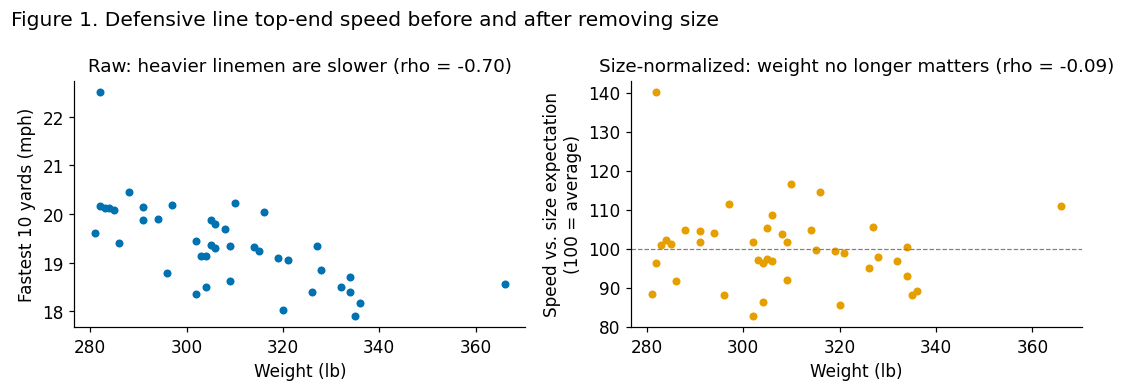

In [3]:
# Figure 1: why size normalization matters (defensive line)
adj_fly = adjust(C, "fly10")
dd = C[(C.pgm == "DL") & C.fly10.notna()]
r_raw = spearmanr(dd.combine_weight, dd.fly10)[0]
r_adj = spearmanr(dd.combine_weight, adj_fly[dd.index], nan_policy="omit")[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(dd.combine_weight, dd.fly10 * YD_TO_MPH, s=18, color=OI[0])
ax[0].set_title(f"Raw: heavier linemen are slower (rho = {r_raw:.2f})")
ax[0].set_xlabel("Weight (lb)"); ax[0].set_ylabel("Fastest 10 yards (mph)")
ax[1].scatter(dd.combine_weight, 100 + 10 * adj_fly[dd.index], s=18, color=OI[1])
ax[1].axhline(100, color="grey", lw=0.8, ls="--")
ax[1].set_title(f"Size-normalized: weight no longer matters (rho = {r_adj:.2f})")
ax[1].set_xlabel("Weight (lb)"); ax[1].set_ylabel("Speed vs. size expectation\n(100 = average)")
fig.suptitle("Figure 1. Defensive line top-end speed before and after removing size", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 3. Seeing juice translate

**Game Juice+** rebuilds the same pieces from regular-season tracking, measured to match the Combine:
- **Explosiveness** is a player's best efforts (95th percentile) of speed at 1.0 s and distance at 1.5 s from a standstill, so loafing snaps don't count.
- **Like is compared with like.** Each play is compared only with plays at the same position, alignment, route and length. DBs are compared only with DBs in the same coverage job (man, deep third, short zone…), and WRs and DBs are split by slot vs. outside. Snaps without a coverage job, snaps under 3 seconds and blowout snaps are dropped.
- **Agility counts only where the Combine drills agree** (not EDGE or TE), so both sides measure the same things.
- **Nobody is thrown out.** Players with few snaps are pulled toward average instead of excluded, and the three pieces are weighted by how repeatable each one is.

That gives 354 players a Game Juice+. It is a stable trait: split-half reliability is 0.82–0.87, and it repeats season to season at about 0.6, which is also the ceiling on how tightly anything measured at the Combine can line up with it.

Figure 2 shows what translation looks like. **Darien Porter** (CB) posted one of the cohort's highest Combine Juice+ scores (131) and is well above average in games (114). Left: his back-pedal drill at the Combine; right: his sharpest cut on an NFL coverage snap; bottom: both speed traces on one clock.

In [4]:
# ---------- Game Juice+ pipeline (no output; the full tracking pass is cached after the first run) ----------
REG = set(games.loc[games.season_type == "REG", "game_id"])
KEYS = ["game_id", "play_id", "nfl_id"]
Q95 = lambda s: s.quantile(0.95)

def circ(d):
    return (d + 180.0) % 360.0 - 180.0

def summarize_chunk(df):
    cols = KEYS + ["n_after", "peak", "alat_max", "s0", "s10", "d15"]
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=cols)
    df = df.sort_values(KEYS + ["time"])
    snap = df.loc[df["event"] == "ball_snap"].groupby(KEYS).time.min().rename("snap")
    df = df.join(snap, on=KEYS)
    df = df[df.time >= df.snap].copy()
    if len(df) == 0:
        return pd.DataFrame(columns=cols)
    gk = [df.game_id, df.play_id, df.nfl_id]
    df["k"] = df.groupby(KEYS).cumcount()
    om = (circ(df.groupby(KEYS)["dir"].diff()) * np.pi / 180.0) / 0.1     # turn rate (rad/s)
    omg = om.groupby(gk)
    om_s = pd.concat([om, omg.shift(1), omg.shift(-1)], axis=1).mean(axis=1)
    df["alat"] = (df.s * om_s.abs()).where(df.s >= 2.0)                     # lateral acceleration
    out = df.groupby(KEYS).agg(n_after=("k", "size"), peak=("s", "max"), alat_max=("alat", "max"))
    out["s0"] = df.loc[df.k == 0].set_index(KEYS).s
    out["s10"] = df.loc[df.k == 10].set_index(KEYS).s
    first15 = df[df.k < 15].groupby(KEYS).s.agg(["sum", "size"])
    out["d15"] = (0.1 * first15["sum"]).where(first15["size"] == 15)   # yards in the first 1.5 s
    return out.reset_index()[cols]

def game_pass(seasons=(2023, 2024, 2025), chunksize=2_000_000):
    parts = []
    for yr in seasons:
        left = None
        for chunk in pd.read_csv(DATA + f"game_tracking_{yr}.csv", usecols=KEYS + ["time", "s", "dir", "event"],
                                 chunksize=chunksize):
            chunk = chunk[chunk.game_id.isin(REG)]
            if left is not None:
                chunk = pd.concat([left, chunk], ignore_index=True)
            if len(chunk) == 0:
                left = None
                continue
            last = chunk.iloc[-1]
            m = (chunk.game_id == last.game_id) & (chunk.play_id == last.play_id)
            left, body = chunk[m], chunk[~m]
            parts.append(summarize_chunk(body))
        parts.append(summarize_chunk(left))
    out = pd.concat([p for p in parts if len(p)], ignore_index=True)
    return out.drop_duplicates(KEYS)

cache_file = f"{CACHE}/game_play_table_v2.csv"   # v2 adds distance at 1.5 s
if os.path.exists(cache_file):
    PT = pd.read_csv(cache_file)
else:
    PT = game_pass(); PT.to_csv(cache_file, index=False)

# Role flags: which snaps match the movement each Combine drill measures
pp = pd.read_csv(DATA + "player_play.csv", usecols=KEYS + ["lined_up_position", "route_ran", "player_get_off",
                                                           "coverage_assignment", "pass_rushers_encountered"])
PT = (PT.merge(games[["game_id", "season"]], on="game_id")
        .merge(D[["nfl_id", "pgm", "nfl_position", "draft_year"]], on="nfl_id")
        .merge(pp, on=KEYS, how="left"))
PT["coverage_assignment"] = PT.coverage_assignment.replace("NO_ASSIGNMENT", np.nan)   # no coverage job
PT["role"] = (((PT.pgm.isin(["WR", "TE"])) & PT.route_ran.notna())
              | ((PT.pgm.isin(["DL", "EDGE"])) & PT.player_get_off.notna())
              | ((PT.pgm == "DB") & PT.coverage_assignment.notna())
              | ((PT.pgm == "OL") & PT.pass_rushers_encountered.notna()))
# Blowouts: per-play win probability if the file has it, else per-play score margin, else final game margin
pp_cols = list(pd.read_csv(DATA + "player_play.csv", nrows=2).columns)
wp_col = next((c for c in pp_cols if "win_prob" in c.lower()), None)
hs = next((c for c in pp_cols if "score" in c.lower() and "home" in c.lower()), None)
vs = next((c for c in pp_cols if "score" in c.lower() and ("visitor" in c.lower() or "away" in c.lower())), None)
if wp_col:
    wp = pd.read_csv(DATA + "player_play.csv", usecols=KEYS + [wp_col]).drop_duplicates(["game_id", "play_id"])
    PT = PT.merge(wp[["game_id", "play_id", wp_col]], on=["game_id", "play_id"], how="left")
    blow = np.minimum(PT[wp_col], 1 - PT[wp_col]) < BLOWOUT_WP
    BLOWOUT_RULE = f"win probability below {BLOWOUT_WP:.0%} for either team ({wp_col})"
elif hs and vs:
    sc = pd.read_csv(DATA + "player_play.csv", usecols=KEYS + [hs, vs]).drop_duplicates(["game_id", "play_id"])
    PT = PT.merge(sc[["game_id", "play_id", hs, vs]], on=["game_id", "play_id"], how="left")
    blow = (PT[hs] - PT[vs]).abs() >= BLOWOUT_MARGIN
    BLOWOUT_RULE = f"score margin of {BLOWOUT_MARGIN}+ at the snap ({hs}, {vs})"
else:
    gh = next((c for c in games.columns if "score" in c.lower() and "home" in c.lower()), None)
    gv = next((c for c in games.columns if "score" in c.lower() and ("visitor" in c.lower() or "away" in c.lower())), None)
    if gh and gv:
        mg = (games.set_index("game_id")[gh] - games.set_index("game_id")[gv]).abs()
        blow = PT.game_id.map(mg) >= BLOWOUT_MARGIN + 7
        BLOWOUT_RULE = f"final margin of {BLOWOUT_MARGIN + 7}+ (no per-play score in the files)"
    else:
        blow = pd.Series(False, index=PT.index); BLOWOUT_RULE = "none (no score columns found)"
BLOWOUT_SHARE = float(blow.fillna(False).mean())
PT = PT[~blow.fillna(False).astype(bool)].copy()

# DBs: only snaps with a coverage job; WRs and DBs split by slot vs outside
PT = PT[~((PT.pgm == "DB") & PT.coverage_assignment.isna())].copy()
lup = PT.lined_up_position.astype(str).str.upper()
slot = np.where(lup.str.contains("SCB|SLOT|NB") | lup.str.match(r"^S[LR]"), "SLOT", "WIDE")
PT["align"] = np.select([PT.pgm.isin(["DL", "EDGE"]), PT.pgm == "WR", PT.pgm == "DB"],
                        [PT.lined_up_position.fillna("UNK"), slot,
                         PT.coverage_assignment.astype(str) + "|" + slot], "ALL")
ALIGN_COUNTS = PT[PT.pgm.isin(["WR", "DB"])].groupby(["pgm", "align"]).size()
PT = PT[PT.n_after >= MIN_FRAMES].copy()                                    # drop dead plays (< 3 s)
PT["len_s"] = np.minimum(PT.n_after // 10, 10)
PT["route"] = np.where(PT.pgm.isin(["WR", "TE"]), PT.route_ran.fillna("NO_ROUTE"), "NONE")

def demean(df, col, key_sets, min_cell=100):
    """Subtract the mean of `col` in the most specific cell with >= min_cell plays, else fall back."""
    mu = df.groupby(key_sets[-1])[col].transform("mean")
    for keys in reversed(key_sets[:-1]):
        m = df.groupby(keys)[col].transform("mean")
        n = df.groupby(keys)[col].transform("count")
        mu = m.where(n >= min_cell, mu)
    return df[col] - mu

def backfit(df, col, factors, min_cell=100, base=("nfl_position", "align")):
    base = list(base)
    tmp = df[list(dict.fromkeys(base + ["nfl_position"] + list(factors)))].copy()
    tmp["_r"] = demean(df, col, [base, ["nfl_position"]], min_cell)
    for _ in range(1 if len(factors) <= 1 else 3):
        for f in factors:
            tmp["_r"] = demean(tmp, "_r", [base + [f], base, ["nfl_position"]], min_cell)
    return tmp["_r"]

def add_adjusted(PT, route_adj, length_adj=False):
    P = PT.copy()
    factors = (["route"] if route_adj else []) + (["len_s"] if length_adj else [])
    P["peak_c"], P["alat_c"], P["s10_c"] = np.nan, np.nan, np.nan
    A_ = P.n_after >= 20
    P.loc[A_, "peak_c"] = backfit(P[A_], "peak", factors)
    P.loc[A_, "alat_c"] = backfit(P[A_], "alat_max", factors)
    ok = P.role & (P.s0 < 1.0) & P.s10.notna()
    rk = ["route"] if route_adj else []
    keysets = [["nfl_position", "align"] + rk, ["nfl_position", "align"], ["nfl_position"]]
    P.loc[ok, "s10_c"] = demean(P[ok], "s10", keysets)
    ok15 = ok & P.d15.notna()
    P["d15_c"] = np.nan
    P.loc[ok15, "d15_c"] = demean(P[ok15], "d15", keysets)
    return P

def game_components(PT, min_burst, min_plays, route_adj=False, length_adj=False):
    P = add_adjusted(PT, route_adj, length_adj)
    B = P[P.role & (P.s0 < 1.0) & P.s10.notna()]
    gb = B.groupby("nfl_id").agg(nb=("s10_c", "size"), g_v1=("s10_c", Q95), g_d15=("d15_c", Q95))   # best efforts
    A_ = P[P.n_after >= 20]
    ga = A_.groupby("nfl_id").agg(npl=("peak_c", "size"), g_top=("peak_c", Q95), g_agil=("alat_c", Q95))
    G = ga.join(gb, how="inner")
    G = G[(G.nb >= min_burst) & (G.npl >= min_plays)].reset_index()
    G = G.merge(D[["nfl_id", "display_name", "nfl_position", "pgm", "draft_year", "combine_weight",
                   "combine_height"]], on="nfl_id")
    for c_ in ["g_top", "g_agil"]:
        G[c_] = G[c_] - G.groupby("nfl_position")[c_].transform("mean")
    return G

G = game_components(PT, GAME_MIN_BURST, GAME_MIN_PLAYS, route_adj=ROUTE_ADJ, length_adj=LENGTH_ADJ)

def split_half_plays(PT, ids, col, stat, reps=30, burst=False):
    sub = PT[PT.nfl_id.isin(ids)]
    sub = sub[sub.role & (sub.s0 < 1.0) & sub.s10.notna()] if burst else sub[sub.n_after >= 20]
    sub = sub[["nfl_id", col]].dropna().reset_index(drop=True)
    out = []
    for _ in range(reps):
        sub["h"] = rng.integers(0, 2, len(sub))
        g = sub.groupby(["nfl_id", "h"])[col].agg(stat).unstack("h").dropna()
        r = spearmanr(g[0], g[1])[0]
        out.append(2 * r / (1 + r))
    return float(np.nanmean(out))

PTa = add_adjusted(PT, ROUTE_ADJ, LENGTH_ADJ)
GREL = {"top": split_half_plays(PTa, G.nfl_id, "peak_c", Q95),
        "expl": float(np.mean([split_half_plays(PTa, G.nfl_id, "s10_c", Q95, burst=True),
                               split_half_plays(PTa, G.nfl_id, "d15_c", Q95, burst=True)])),
        "agil": split_half_plays(PTa, G.nfl_id, "alat_c", Q95)}
NMED = {"top": float(G.npl.median()), "expl": float(G.nb.median()), "agil": float(G.npl.median())}
# agility counts only where the Combine drills agree with each other (and it repeats in games)
GATE_G = {g_: bool(gate.get(g_, False)) and GREL["agil"] >= 0.5 for g_ in PGM.values()}

def build_game_juice(Gin, class_adj, gate_agil, shrink=True):
    g = Gin.copy()
    g["top_z"] = adjust(g, "g_top", use_class=class_adj)
    g["expl_z"] = pd.concat([adjust(g, "g_v1", use_class=class_adj), adjust(g, "g_d15", use_class=class_adj)],
                            axis=1).mean(axis=1)
    gated = g.pgm.map(gate_agil) if isinstance(gate_agil, dict) else pd.Series(bool(gate_agil), index=g.index)
    g["agil_z"] = adjust(g, "g_agil", use_class=class_adj).where(gated.fillna(False).astype(bool))
    if shrink:   # few snaps -> pulled toward average: a player's reliability is n / (n + lam)
        for zc, n_col, key in [("top_z", "npl", "top"), ("expl_z", "nb", "expl"), ("agil_z", "npl", "agil")]:
            R_ = max(GREL[key], 1e-3)
            lam = NMED[key] * (1 - R_) / R_
            g[zc] = g[zc] * g[n_col] / (g[n_col] + lam)
    W = {"top_z": max(GREL["top"], 0), "expl_z": max(GREL["expl"], 0), "agil_z": max(GREL["agil"], 0)}
    Z = g[list(W)]
    wts = pd.DataFrame({c_: np.where(Z[c_].notna(), W[c_], 0.0) for c_ in W}, index=g.index)
    g["raw"] = (Z.fillna(0) * wts).sum(axis=1) / wts.sum(axis=1).replace(0, np.nan)   # weighted by repeatability
    g["game_juice"] = scale100(g, "raw")
    for c_, name in [("top_z", "g_top_plus"), ("expl_z", "g_expl_plus"), ("agil_z", "g_agil_plus")]:
        g[name] = 100 + 10 * g[c_]
    return g[["nfl_id", "display_name", "nfl_position", "pgm", "draft_year", "game_juice",
              "g_top_plus", "g_expl_plus", "g_agil_plus", "npl", "nb"]]

GJ = build_game_juice(G, GAME_CLASS_ADJ, GATE_G)

# Season-to-season repeatability of the Game Juice+ composite (the ceiling for any Combine metric)
seasonal = []
for seas, sub in PT.groupby("season"):
    Gs = game_components(sub, MIN_BURST_SEASON, MIN_PLAYS_SEASON, route_adj=ROUTE_ADJ, length_adj=LENGTH_ADJ)
    if len(Gs) < 10:
        continue
    Gs["comp"] = build_game_juice(Gs, GAME_CLASS_ADJ, GATE_G).set_index("nfl_id").game_juice.reindex(Gs.nfl_id).values
    Gs["season"] = seas
    seasonal.append(Gs[["nfl_id", "season", "comp"]])
PERSIST = {}
if seasonal:
    w = pd.concat(seasonal).pivot(index="nfl_id", columns="season", values="comp")
    for a_, b_ in [(2023, 2024), (2024, 2025)]:
        if a_ in w and b_ in w and len(w[[a_, b_]].dropna()) >= 10:
            x = w[[a_, b_]].dropna(); PERSIST[f"{a_}->{b_}"] = (len(x), spearmanr(x[a_], x[b_])[0])

# Players with both scores
FA2 = FINAL[["nfl_id", "juice_final", "E_plus", "T_plus", "A_plus"]]
M = FA2.merge(GJ, on="nfl_id", how="inner")
STICK = {}
for g, d in list(M.groupby("pgm")) + [("ALL", M)]:
    if len(d) >= 15:
        r = spearmanr(d.juice_final, d.game_juice, nan_policy="omit")[0]; STICK[g] = (len(d), r, *fisher_ci(r, len(d)))
CLASS_R = {int(y): spearmanr(d.juice_final, d.game_juice, nan_policy="omit")[0] for y, d in M.groupby("draft_year") if len(d) >= 15}
PT_rk = PT[PT.draft_year.notna() & (PT.season == PT.draft_year)]
G_rk = game_components(PT_rk, MIN_BURST_SEASON, MIN_PLAYS_SEASON, route_adj=ROUTE_ADJ, length_adj=LENGTH_ADJ)
ROOKIE_R = np.nan
if len(G_rk) >= 45:
    Mr = FA2.merge(build_game_juice(G_rk, True, GATE_G), on="nfl_id")
    zz = [(np.arctanh(spearmanr(d.juice_final, d.game_juice, nan_policy="omit")[0]), len(d) - 3)
          for _, d in Mr.groupby("draft_year") if len(d) >= 15]
    ROOKIE_R = np.tanh(sum(z * w_ for z, w_ in zz) / sum(w_ for _, w_ in zz))

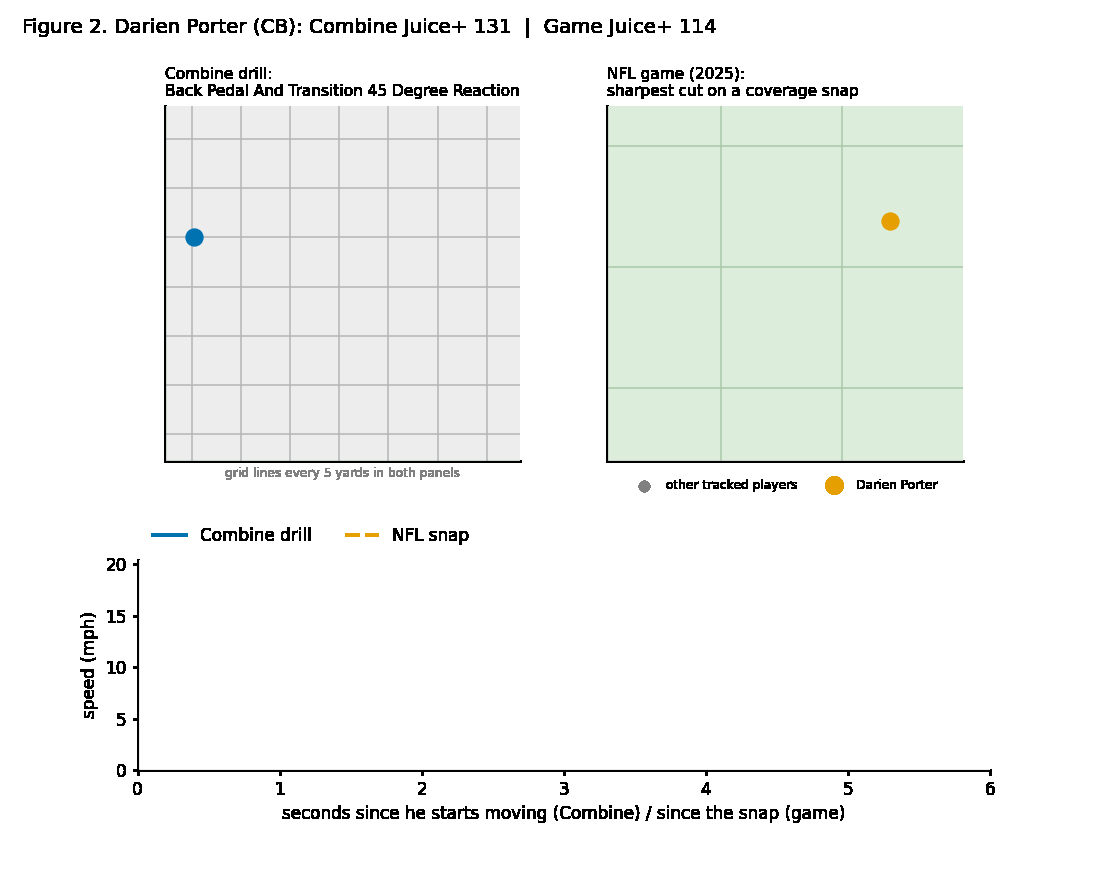

In [5]:
# Figure 2: the same player in a position drill at the Combine and on a matching NFL snap
PLAYER = "Darien Porter"   # any player in M; falls back to the best "high Combine / high game" player
DRILL_SUBS = {"DB": ["BACK_PEDAL"], "WR": ["ROUTE"], "TE": ["ROUTE"], "DL": ["BAG", "PASS_RUSH", "WAVE"],
              "EDGE": ["BAG", "PASS_RUSH", "WAVE"], "OL": ["PASS_PRO", "MIRROR", "WAVE"]}
SNAP_WORD = {"DB": "coverage", "WR": "route", "TE": "route", "DL": "pass-rush", "EDGE": "pass-rush", "OL": "pass-pro"}
row = M[M.display_name == PLAYER]
if row.empty:
    row = M.assign(_both=np.minimum(M.juice_final, M.game_juice)).nlargest(1, "_both")
pid, pname, ppos, pg = int(row.nfl_id.iloc[0]), row.display_name.iloc[0], row.nfl_position.iloc[0], row.pgm.iloc[0]
cj, gj = row.juice_final.iloc[0], row.game_juice.iloc[0]
gif_path = f"{CACHE}/juice_drill_vs_play_v2_{pid}.gif"

if not os.path.exists(gif_path):
    # Combine: his position drill with the hardest braking and cutting (95th-percentile acceleration)
    mine_d = ad[ad.nfl_id == pid]
    pos_d = mine_d[mine_d.drill_name.apply(lambda n: any(s_ in n for s_ in DRILL_SUBS.get(pg, [])))]
    pick_d = pos_d if len(pos_d) else mine_d
    if len(pick_d):
        ev = pick_d.acc95.idxmax(); dname = pick_d.loc[ev, "drill_name"]
    else:                                             # no usable drill: fall back to his 40
        ev = a40[a40.nfl_id == pid].fly10.idxmax(); dname = "FORTY_YARD_DASH"
    cf = ct[ct.event_id == ev].sort_values("t")
    on = np.where(cf.s.values >= 1.0)[0]
    cf = cf.iloc[max(on[0] - 3, 0):] if len(on) else cf
    cf = cf[cf.t - cf.t.iloc[0] <= 6.0]                 # the drill itself, not the jog out afterwards
    cx, cy = cf.x.values, cf.y.values
    cs, ctt = cf.s.values * YD_TO_MPH, cf.t.values - cf.t.values[0]

    # Game: his sharpest cuts at speed on role-matched snaps (same route as the drill for WR/TE)
    pool = PT[(PT.nfl_id == pid) & PT.role]
    if pg in ("WR", "TE"):
        same = pool[pool.route.astype(str).apply(lambda r: r not in ("NO_ROUTE", "NONE") and r.split("_")[0] in dname)]
        pool = same if len(same) else pool
    cands = pool.nlargest(5, "alat_max")[["game_id", "play_id", "season"]].astype(int)
    if cands.empty:
        raise ValueError(f"No role-matched game snaps for {pname}; set PLAYER to someone else.")
    gp_all = []
    for seas_ in cands.season.unique():     # full pass, no early exit: rows of one play may not be contiguous
        for chunk in pd.read_csv(DATA + f"game_tracking_{seas_}.csv", chunksize=2_000_000,
                                 usecols=["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "event"]):
            hit = chunk[chunk.game_id.isin(cands.game_id)]
            if len(hit):
                gp_all.append(hit.merge(cands[["game_id", "play_id"]], on=["game_id", "play_id"]))
    gp_all = pd.concat(gp_all, ignore_index=True)
    gp_all["time"] = pd.to_datetime(gp_all.time)
    me = pd.DataFrame()
    for _, cand in cands.iterrows():
        gp = gp_all[(gp_all.game_id == cand.game_id) & (gp_all.play_id == cand.play_id)].copy()
        mine = gp[gp.nfl_id == pid]
        if mine.empty:
            continue
        snap_t = mine.loc[mine.event == "ball_snap", "time"].min()
        if pd.isna(snap_t):
            snap_t = gp.loc[gp.event == "ball_snap", "time"].min()
        if pd.isna(snap_t):
            snap_t = mine.time.min()
        gp["t"] = (gp.time - snap_t).dt.total_seconds().round(1)
        gp = gp[(gp.t >= 0) & (gp.t <= 6)].sort_values("t")
        me = gp[gp.nfl_id == pid].drop_duplicates("t")
        if len(me) >= 10:
            seas = int(cand.season)
            break
    if len(me) < 10:
        raise ValueError(f"Could not find usable tracking frames for {pname}'s top snaps; set PLAYER to someone else.")
    others = {t: d for t, d in gp[gp.nfl_id != pid].groupby("t")}
    gx, gy, gs, gtt = me.x.values, me.y.values, me.s.values * YD_TO_MPH, me.t.values

    def field(ax, xs, ys, face, line):
        pad = 3
        xc, yc = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
        half = max(xs.max() - xs.min(), ys.max() - ys.min()) / 2 + pad
        ax.set_xlim(xc - half, xc + half); ax.set_ylim(yc - half, yc + half); ax.set_aspect("equal")
        ax.set_facecolor(face); ax.set_xticks([]); ax.set_yticks([])
        for v in range(int(np.floor((xc - half) / 5) * 5), int(xc + half) + 1, 5):
            ax.axvline(v, color=line, lw=1.0, zorder=0)
        for v in range(int(np.floor((yc - half) / 5) * 5), int(yc + half) + 1, 5):
            ax.axhline(v, color=line, lw=1.0, zorder=0)

    fig = plt.figure(figsize=(10, 8))
    gsp = fig.add_gridspec(2, 2, height_ratios=[2.2, 1.3], hspace=0.35, wspace=0.08)
    axc, axg, axs = fig.add_subplot(gsp[0, 0]), fig.add_subplot(gsp[0, 1]), fig.add_subplot(gsp[1, :])
    fig.suptitle(f"Figure 2. {pname} ({ppos}): Combine Juice+ {cj:.0f}  |  Game Juice+ {gj:.0f}",
                 x=0.02, ha="left", fontsize=13)
    field(axc, cx, cy, "#eeeeee", "#b5b5b5")
    axc.set_title("Combine drill:\n" + dname.replace("_", " ").title(), loc="left", fontsize=10)
    field(axg, gx, gy, "#dcefdc", "#a9c9a9")
    axg.set_title(f"NFL game ({seas}):\nsharpest cut on a {SNAP_WORD.get(pg, 'game')} snap", loc="left", fontsize=10)
    c_trail, = axc.plot([], [], color=OI[0], lw=2.2); c_dot, = axc.plot([], [], "o", color=OI[0], ms=11)
    o_dots = axg.scatter([], [], s=40, color="grey", alpha=0.6, label="other tracked players")
    g_trail, = axg.plot([], [], color=OI[1], lw=2.2)
    g_dot, = axg.plot([], [], "o", color=OI[1], ms=11, label=pname)
    axg.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=8, frameon=False)
    axc.set_xlabel("grid lines every 5 yards in both panels", fontsize=8, color="grey")
    tmax = max(ctt.max(), gtt.max())
    axs.set_xlim(0, tmax); axs.set_ylim(0, max(cs.max(), gs.max()) * 1.15)
    axs.set_xlabel("seconds since he starts moving (Combine) / since the snap (game)"); axs.set_ylabel("speed (mph)")
    c_line, = axs.plot([], [], color=OI[0], lw=2.5, label="Combine drill")
    g_line, = axs.plot([], [], color=OI[1], lw=2.5, ls="--", label="NFL snap")
    axs.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)

    n_frames = int(round(tmax * 10)) + 15          # hold the last frame for 1.5 s
    def frame(i):
        ic, ig = min(i, len(cx) - 1), min(i, len(gx) - 1)
        c_trail.set_data(cx[:ic + 1], cy[:ic + 1]); c_dot.set_data([cx[ic]], [cy[ic]])
        g_trail.set_data(gx[:ig + 1], gy[:ig + 1]); g_dot.set_data([gx[ig]], [gy[ig]])
        od = others.get(gtt[ig])
        o_dots.set_offsets(od[["x", "y"]].values if od is not None else np.empty((0, 2)))
        c_line.set_data(ctt[:ic + 1], cs[:ic + 1]); g_line.set_data(gtt[:ig + 1], gs[:ig + 1])
        return c_trail, c_dot, g_trail, g_dot, o_dots, c_line, g_line
    anim = animation.FuncAnimation(fig, frame, frames=n_frames, interval=100, blit=True)
    anim.save(gif_path, writer=animation.PillowWriter(fps=10))
    plt.close(fig)

display(Image(filename=gif_path))

## 4. Does Combine juice show up in games?

**Yes.** Across the 303 players with both scores, the rank correlation between Combine and Game Juice+ is **0.31** (95% interval 0.20 to 0.41), half of the 0.6 ceiling set by how well game movement predicts *itself* from one season to the next. It is steady across draft classes (0.35, 0.29, 0.29), holds on rookie seasons alone (0.20), and holds when the formula is rebuilt without the class being scored (section 5).

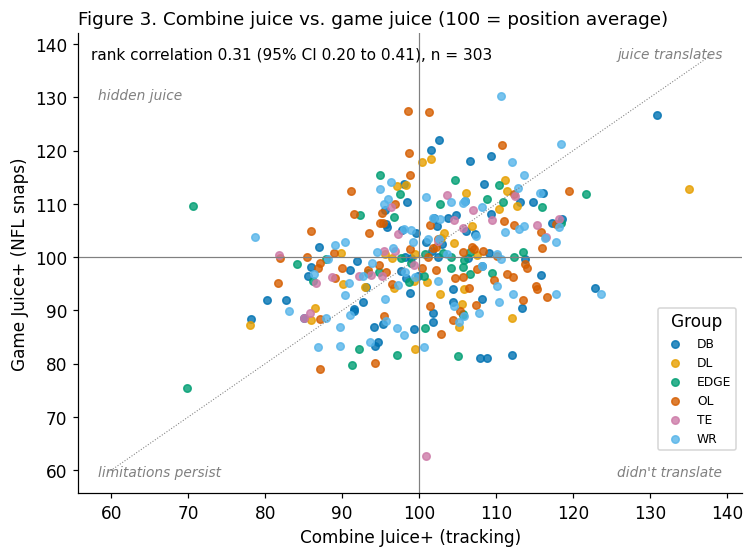

In [6]:
# Figure 3: Combine Juice+ vs Game Juice+
fig, ax = plt.subplots(figsize=(7, 5.2))
for g, d in M.groupby("pgm"):
    ax.scatter(d.juice_final, d.game_juice, s=24, alpha=0.8, color=GROUP_COL[g], label=g)
ax.axhline(100, color="grey", lw=0.8); ax.axvline(100, color="grey", lw=0.8)
lo, hi = min(M.juice_final.min(), M.game_juice.min()) - 3, max(M.juice_final.max(), M.game_juice.max()) + 3
ax.plot([lo, hi], [lo, hi], color="grey", lw=0.7, ls=":")
n, r, rl, rh = STICK["ALL"]
ax.text(0.02, 0.97, f"rank correlation {r:.2f} (95% CI {rl:.2f} to {rh:.2f}), n = {n}",
        transform=ax.transAxes, va="top", fontsize=10)
for txt, (xx, yy) in {"juice translates": (0.97, 0.97), "hidden juice": (0.03, 0.88),
                      "didn't translate": (0.97, 0.03), "limitations persist": (0.03, 0.03)}.items():
    ax.text(xx, yy, txt, transform=ax.transAxes, ha="right" if xx > 0.5 else "left",
            va="top" if yy > 0.5 else "bottom", color="grey", fontsize=9, style="italic")
ax.set_xlabel("Combine Juice+ (tracking)"); ax.set_ylabel("Game Juice+ (NFL snaps)")
ax.set_title("Figure 3. Combine juice vs. game juice (100 = position average)", loc="left")
ax.legend(title="Group", fontsize=8, loc="lower right", bbox_to_anchor=(1, 0.08))
plt.tight_layout(); plt.show()

The more useful view for a draft room is by band (Figure 4). Average Game Juice+ climbs steadily from the low band (94.3) to the elite band (104.7):

- **Red flag:** 78% of players under 90 at the Combine were below average in games, **1.57× the base rate** (interval 1.31 to 1.84).
- **Green flag:** 69% of players at 110+ were above average in games, **1.37× the base rate** (1.16 to 1.60).
- **Elite stays elite:** 31% of elite Combine players were elite in games, **1.82× the base rate** (1.25 to 2.41).

As a ranking tool (nothing is fitted to the game outcome), Combine Juice+ picks out above-average game movers with an AUC of **0.67**, where 0.5 is a coin flip.

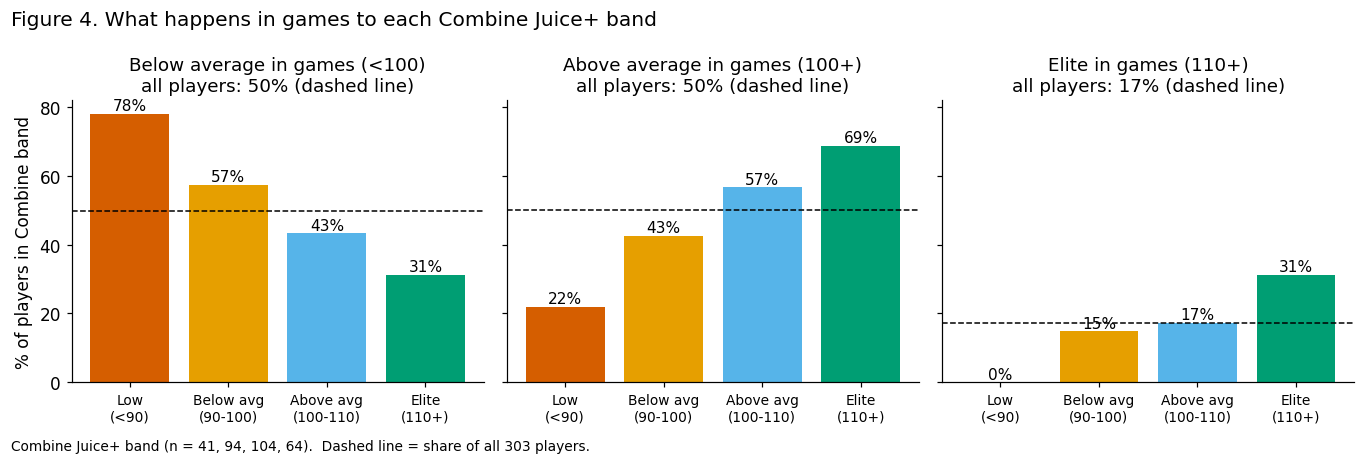

In [7]:
# Figure 4: outcome rates by Combine Juice+ band
BANDS = [-np.inf, LOW_JUICE, BELOW_AVG, ELITE, np.inf]
SHORT = ["Low\n(<90)", "Below avg\n(90-100)", "Above avg\n(100-110)", "Elite\n(110+)"]
M["c_band"] = pd.cut(M.juice_final, BANDS, labels=SHORT, right=False)
M["g_below"], M["g_above"], M["g_elite"] = M.game_juice < BELOW_AVG, M.game_juice >= BELOW_AVG, M.game_juice >= ELITE

def risk_ratio(group_mask, outcome, reps=2000):
    g, o = group_mask.values, outcome.values
    est, boots = o[g].mean() / o.mean(), []
    for _ in range(reps):
        i = rng.integers(0, len(M), len(M))
        gi, oi = g[i], o[i]
        if gi.sum() and oi.mean() > 0:
            boots.append(oi[gi].mean() / oi.mean())
    return est, np.percentile(boots, [2.5, 97.5])
ANSWERS = {}
def say(key, group_mask, outcome):
    n = int(group_mask.sum()); k = int(outcome[group_mask].sum())
    rr, (rlo, rhi) = risk_ratio(group_mask, outcome)
    ANSWERS[key] = dict(k=k, n=n, pct=100 * k / n, ci=wilson(k, n), rr=rr, rr_ci=(rlo, rhi))
say("below_to_below", M.juice_final < BELOW_AVG, M.g_below)
say("low_to_below", M.juice_final < LOW_JUICE, M.g_below)
say("elite_to_above", M.juice_final >= ELITE, M.g_above)
say("elite_to_elite", M.juice_final >= ELITE, M.g_elite)
say("above_to_above", M.juice_final >= BELOW_AVG, M.g_above)

def auc_ci(y, s, reps=1000, seed=3):
    y = np.asarray(y).astype(int); s = np.asarray(s, dtype=float)
    ok = ~np.isnan(s); y, s = y[ok], s[ok]
    if len(y) < 10 or y.min() == y.max():
        return np.nan, np.nan, np.nan
    r_, boots = np.random.default_rng(seed), []
    for _ in range(reps):
        i = r_.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            boots.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), np.percentile(boots, 2.5), np.percentile(boots, 97.5)
M["c_p"] = M.groupby("pgm").juice_final.rank(pct=True)
AUC_ALL = auc_ci(M.g_above, M.c_p)

outs = [("g_below", "Below average in games (<100)"), ("g_above", "Above average in games (100+)"),
        ("g_elite", "Elite in games (110+)")]
cols = [OI[3], OI[1], OI[5], OI[2]]
fig, ax = plt.subplots(1, 3, figsize=(12.5, 4), sharey=True)
for a, (c_, lab) in zip(ax, outs):
    vals = [100 * M.loc[M.c_band == b, c_].mean() for b in SHORT]
    bars = a.bar(range(4), vals, color=cols)
    base = 100 * M[c_].mean()
    a.axhline(base, color="black", ls="--", lw=1)
    for b_, v in zip(bars, vals):
        a.text(b_.get_x() + b_.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=10)
    a.set_xticks(range(4)); a.set_xticklabels(SHORT, fontsize=9); a.set_title(f"{lab}\nall players: {base:.0f}% (dashed line)")
ax[0].set_ylabel("% of players in Combine band")
fig.text(0.01, -0.02, "Combine Juice+ band (n = " + ", ".join(str(int((M.c_band == b).sum())) for b in SHORT)
         + f").  Dashed line = share of all {len(M)} players.", fontsize=9)
fig.suptitle("Figure 4. What happens in games to each Combine Juice+ band", x=0.01, ha="left")
plt.tight_layout(); plt.show()

**Which piece carries?** If the same-instrument idea works, each Combine piece should line up best with its own game counterpart, the diagonal in Figure 5. **Top-end speed (0.25) and explosiveness (0.20) carry**; agility only weakly (0.15).

**Where does it carry?** In every group but one. Receivers (0.39, interval 0.16 to 0.57), defensive line (0.36, 0.02 to 0.63), defensive backs (0.36, 0.13 to 0.55) and edge rushers (0.33, 0.02 to 0.58) all clear zero, and tight ends are highest on a small sample (0.72, n = 24). Offensive linemen have the most limited translation from Combine to Game Juice+ (0.01), because games rarely ask them to reach top speed: their fastest snap of the season reaches only about two-thirds of their Combine speed. That is a limit of game tracking, not of OL juice: both honored linemen in the cohort, Darnell Wright (All-Pro, 115) and Joe Alt (Pro Bowl, 117), graded elite at the Combine.

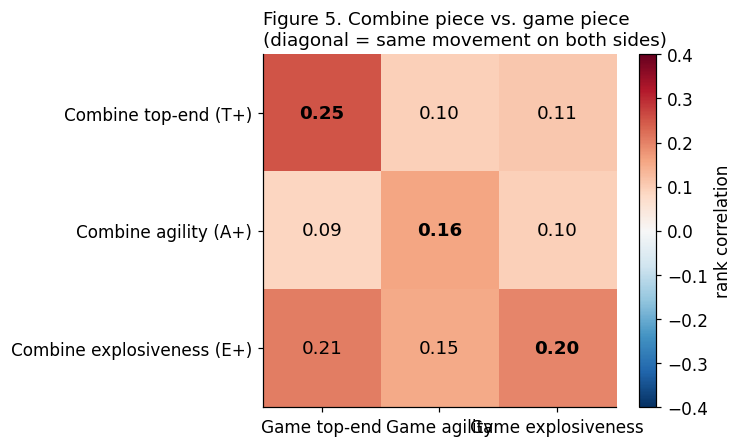

In [8]:
# Figure 5: Combine piece vs game piece
rows_lab = ["Combine top-end (T+)", "Combine agility (A+)", "Combine explosiveness (E+)"]
cols_lab = ["Game top-end", "Game agility", "Game explosiveness"]
cmat = np.full((3, 3), np.nan)
for i, cc in enumerate(["T_plus", "A_plus", "E_plus"]):
    for j, gc in enumerate(["g_top_plus", "g_agil_plus", "g_expl_plus"]):
        d = M[[cc, gc]].dropna()
        if len(d) >= 15:
            cmat[i, j] = spearmanr(d[cc], d[gc])[0]
fig, ax = plt.subplots(figsize=(6.2, 4.2))
im = ax.imshow(cmat, vmin=-0.4, vmax=0.4, cmap="RdBu_r")
ax.set_xticks(range(3)); ax.set_xticklabels(cols_lab); ax.set_yticks(range(3)); ax.set_yticklabels(rows_lab)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cmat[i, j]:.2f}", ha="center", va="center", fontsize=12,
                fontweight="bold" if i == j else "normal")
plt.colorbar(im, ax=ax, fraction=0.046, label="rank correlation")
ax.set_title("Figure 5. Combine piece vs. game piece\n(diagonal = same movement on both sides)", loc="left")
plt.tight_layout(); plt.show()

## 5. Juice+ vs. the stopwatch

On the same 279 players, Juice+ ranks game movement at **0.31**, against **0.25** for a RAS-style score and **0.19** for the NGS Athleticism Score (Figure 6). Because Juice+ averages in the stopwatch tests, the real question is whether tracking adds to them:

- **It does, measurably.** Trained on two draft classes and tested on the third, adding Juice+ to the traditional Combine results (every stopwatch test, the NGS score and size) plus draft pick improves the prediction of Game Juice+ (gain +0.020, interval 0.004 to 0.035). Its edge over NGS is clear (0.12, interval 0.03 to 0.21); over RAS-style it is positive but within noise (0.06, −0.03 to 0.15).
- **No leakage from the held-out class.** Rebuilding the whole Combine Juice+ formula on two classes and scoring the third gives a pooled correlation of 0.29 (0.18 to 0.39) and nearly the same gain (+0.017, 0.006 to 0.028).
- **For top speed alone, tracking and the stopwatch are even** (0.22 vs 0.23; receivers 0.56 vs 0.52), which is why Juice+ averages them rather than choosing one.
- **It is fair to every body type.** Juice+ stays within 0.16 of zero against weight in every group, while NGS ranges from −0.36 to +0.43 and RAS-style from −0.78 to +0.01.

One caveat cuts against us: Combine and Game Juice+ share a measurement method, which may flatter Juice+ in this comparison.

**Do the position drills add anything?** We tested whether players *rank* the same way in each drill as on its matching snaps (e.g., DB break drills vs. coverage snaps; WR route drills vs. the same route), including whether drill extremes stay extreme. Across 21 pre-specified tests and a 195-test scan, nothing beat chance after correction. Drill movement, as tracked today, doesn't repeat; that part of the Combine really is the "Underwear Olympics."

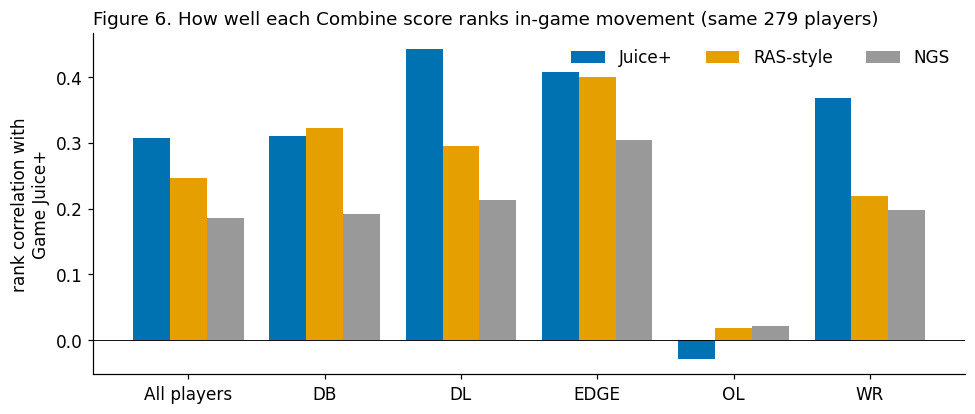

In [9]:
# ---------- Head-to-head against stopwatch scores (silent), then Figure 6 ----------
def ras_style(df):
    out = pd.Series(np.nan, index=df.index)
    for g, d in df.groupby("pgm"):
        pct = {c_: d[c_].rank(pct=True, ascending=(c_ not in LOWER_BETTER))
               for c_ in LOWER_BETTER + HIGHER_BETTER if c_ in d.columns and d[c_].notna().sum() >= 15}
        if pct:
            P = pd.DataFrame(pct)
            out.loc[d.index] = (10 * P.mean(axis=1)).where(P.notna().sum(axis=1) >= 4)
    return out

CMP = FINAL.drop(columns=[c for c in TESTS.columns if c in FINAL.columns and c != "nfl_id"]).merge(TESTS, on="nfl_id", how="left")
CMP["ras_style"] = ras_style(CMP)
CMP["ngs_adj"] = adjust(CMP, "ngs_athleticism_score")
CMP["ras_adj"] = adjust(CMP, "ras_style")
CMP["forty_adj"] = -adjust(CMP, "forty")
CMP["split_adj"] = -adjust(CMP, "ten_yd_split")
CMP["forty_neg"] = -CMP["forty"]

X = CMP[CMP.ngs_athleticism_score.notna() & CMP.ras_style.notna()].copy()
WEIGHT_R = {g: {s_: spearmanr(d.combine_weight, d[c_])[0] for s_, c_ in
                [("Juice+", "juice_final"), ("NGS", "ngs_athleticism_score"), ("RAS", "ras_style")]}
            for g, d in X.groupby("pgm") if len(d) >= 15}

V = (M[["nfl_id", "pgm", "juice_final", "game_juice", "g_top_plus", "T_plus"]]
     .merge(CMP[["nfl_id", "ngs_athleticism_score", "ras_style", "ngs_adj", "ras_adj", "forty_adj",
                 "split_adj", "forty_neg"]], on="nfl_id", how="left")
     .merge(S[["nfl_id", "juice_unadjusted"]], on="nfl_id", how="left"))
V = V.dropna(subset=["ngs_athleticism_score", "ras_style", "ngs_adj", "ras_adj", "juice_unadjusted"])

def pooled_rho(df, col, outcome="game_juice"):
    return spearmanr(df.groupby("pgm")[col].rank(pct=True), df.groupby("pgm")[outcome].rank(pct=True), nan_policy="omit")[0]
def corr_row(df, col, outcome):
    row = {"ALL": pooled_rho(df, col, outcome)}
    for g, d in df.groupby("pgm"):
        if len(d) >= 15:
            row[g] = spearmanr(d[col], d[outcome], nan_policy="omit")[0]
    return row
SC = {"Juice+": "juice_final", "Juice+ (no size adj.)": "juice_unadjusted", "NGS": "ngs_athleticism_score",
      "NGS (size adj.)": "ngs_adj", "RAS-style": "ras_style", "RAS-style (size adj.)": "ras_adj"}
NGS_TAB = pd.DataFrame({k: corr_row(V, c_, "game_juice") for k, c_ in SC.items()}).T
U = V.dropna(subset=["T_plus", "forty_adj", "split_adj", "forty_neg"])
TOP_TAB = pd.DataFrame({k: corr_row(U, c_, "g_top_plus") for k, c_ in
                        {"Tracked fastest 10": "T_plus", "Official 40 (size adj.)": "forty_adj",
                         "10-yd split (size adj.)": "split_adj", "Official 40 (raw)": "forty_neg"}.items()}).T

rng_b, boots = np.random.default_rng(1), {"NGS": [], "RAS": []}
for _ in range(1000):
    b = V.iloc[rng_b.integers(0, len(V), len(V))]
    j_ = pooled_rho(b, "juice_final")
    boots["NGS"].append(j_ - pooled_rho(b, "ngs_athleticism_score"))
    boots["RAS"].append(j_ - pooled_rho(b, "ras_style"))
EDGE = {k: (NGS_TAB.loc["Juice+", "ALL"] - NGS_TAB.loc[n_, "ALL"], *np.percentile(v, [2.5, 97.5]))
        for k, v, n_ in [("NGS", boots["NGS"], "NGS"), ("RAS", boots["RAS"], "RAS-style")]}

# When the scores disagree
for col, nm in [("juice_final", "j_p"), ("ngs_athleticism_score", "n_p"), ("ras_style", "r_p")]:
    X[nm] = 100 * X.groupby("pgm")[col].rank(pct=True)
X["gap"] = X.j_p - (X.n_p + X.r_p) / 2
Y = X.merge(GJ[["nfl_id", "game_juice"]], on="nfl_id")
Y["g_p"] = 100 * Y.groupby("pgm").game_juice.rank(pct=True)
DISAGREE = {k: (int(m.sum()), Y.g_p[m].mean()) for k, m in
            [("Juice+ higher", Y.gap >= 20), ("agree", Y.gap.abs() < 20), ("Juice+ lower", Y.gap <= -20)]}

# Out-of-class incremental value (train on two classes, predict the third)
IV = M[["nfl_id", "pgm", "draft_year", "juice_final", "game_juice", "npl"]].merge(
    CMP[["nfl_id", "draft_overall_pick", "combine_weight", "combine_height", "ngs_athleticism_score"]
        + [c_ for c_ in LOWER_BETTER + HIGHER_BETTER if c_ in CMP.columns]], on="nfl_id", how="left")
def pct_feature(df, col, lower_better=False):
    return df.groupby("pgm")[col].rank(pct=True, ascending=not lower_better).fillna(0.5)
trad = {c_: pct_feature(IV, c_, c_ in LOWER_BETTER) for c_ in LOWER_BETTER + HIGHER_BETTER if c_ in IV}
trad["ngs"] = pct_feature(IV, "ngs_athleticism_score")
trad["weight"] = IV.groupby("pgm").combine_weight.transform(zs).fillna(0)
trad["height"] = IV.groupby("pgm").combine_height.transform(zs).fillna(0)
X_trad = pd.DataFrame(trad)
X_pick = pd.DataFrame({"log_pick": np.log(IV.draft_overall_pick.fillna(260))})
X_juice = pd.DataFrame({"juice": (IV.juice_final - 100) / 10})
MODELS = {"pick": X_pick, "trad": X_trad, "trad+pick": X_trad.join(X_pick), "juice": X_juice,
          "trad+pick+juice": X_trad.join(X_pick).join(X_juice)}
yv, cls_ = IV.game_juice.values, IV.draft_year.values
def out_of_class(Xm):
    pred, base = np.full(len(IV), np.nan), np.full(len(IV), np.nan)
    for c_ in np.unique(cls_):
        tr, te = cls_ != c_, cls_ == c_
        if tr.sum() < 20:
            continue
        m_ = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 20))).fit(Xm.values[tr], yv[tr])
        pred[te], base[te] = m_.predict(Xm.values[te]), yv[tr].mean()
    return pred, base
def r2(y_, p, b):
    ok = ~np.isnan(p)
    return 1 - ((y_[ok] - p[ok]) ** 2).sum() / ((y_[ok] - b[ok]) ** 2).sum()
OOF = {k: out_of_class(Xm) for k, Xm in MODELS.items()}
R2 = {k: r2(yv, *v) for k, v in OOF.items()}
r_ = np.random.default_rng(5); dg = []
for _ in range(2000):
    i = r_.integers(0, len(yv), len(yv))
    dg.append(r2(yv[i], OOF["trad+pick+juice"][0][i], OOF["trad+pick+juice"][1][i])
              - r2(yv[i], OOF["trad+pick"][0][i], OOF["trad+pick"][1][i]))
GAIN = (R2["trad+pick+juice"] - R2["trad+pick"], *np.percentile(dg, [2.5, 97.5]))

# Figure 6
order = ["ALL", "DB", "DL", "EDGE", "OL", "WR"]
show = NGS_TAB.loc[["Juice+", "RAS-style", "NGS"], [c_ for c_ in order if c_ in NGS_TAB.columns]]
fig, ax = plt.subplots(figsize=(9, 3.9))
xs, wbar = np.arange(show.shape[1]), 0.27
for k, (nm, colr) in enumerate(zip(show.index, [OI[0], OI[1], "#999999"])):
    ax.bar(xs + (k - 1) * wbar, show.loc[nm].values, wbar, color=colr, label=nm)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(xs); ax.set_xticklabels(["All players"] + list(show.columns[1:]))
ax.set_ylabel("rank correlation with\nGame Juice+")
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.set_title(f"Figure 6. How well each Combine score ranks in-game movement (same {len(V)} players)", loc="left")
plt.tight_layout(); plt.show()

In [10]:
# ---------- Fully held-out check (silent): every player's Juice+ comes from a formula fit without his class ----------
def rel40(ids):
    w = w2[w2.nfl_id.isin(ids)]; out = {}
    for f in ["d15", "v1", "fly10"]:
        zsum, wsum = 0.0, 0.0
        for g, d in w.groupby("pgm"):
            if len(d) < 15:
                continue
            x0 = d[f + "_0"] - d.groupby("draft_year")[f + "_0"].transform("mean")
            x1 = d[f + "_1"] - d.groupby("draft_year")[f + "_1"].transform("mean")
            zsum += np.arctanh(spearmanr(x0, x1)[0]) * (len(d) - 3); wsum += len(d) - 3
        out[f] = float(np.tanh(zsum / wsum)) if wsum > 0 else 0.6
    return (out["d15"] + out["v1"]) / 2, out["fly10"]

def gate_fn(ids):
    gt, rb_ = {g: False for g in FAM}, {g: np.nan for g in FAM}
    for g, wide in WIDE.items():
        w = wide[wide.index.isin(ids)]
        cors = []
        for i in range(w.shape[1]):
            for j in range(i + 1, w.shape[1]):
                both = w.iloc[:, [i, j]].dropna()
                if len(both) >= MIN_OVERLAP:
                    cors.append(np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1])
        rb = float(np.mean(cors)) if cors else np.nan
        k = float(w.notna().sum(axis=1).median()) if len(w) else 0
        alpha = k * rb / (1 + (k - 1) * rb) if np.isfinite(rb) and k >= 2 else np.nan
        gt[g], rb_[g] = bool(np.isfinite(alpha) and alpha >= GATE_ALPHA), rb
    return gt, rb_

def adjust_frozen(df, col, train):
    # size model fit on the training classes only; the held-out class is standardized against itself
    out = pd.Series(np.nan, index=df.index)
    for g, d in df.groupby("pgm"):
        d = d.dropna(subset=[col, "combine_weight", "combine_height"])
        tr, te = d[train.loc[d.index]], d[~train.loc[d.index]]
        if len(tr) < 15 or len(te) < 3:
            continue
        feats = lambda x: np.column_stack([x.combine_weight, x.combine_height,
                                           (x.combine_weight - tr.combine_weight.mean()) ** 2 / 100])
        if len(tr) >= 25:
            mdl = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(feats(tr), tr[col])
            p = mdl.predict(feats(te))
        else:
            p = tr[col].mean()
        r = te[col].values - p
        out.loc[te.index] = (r - r.mean()) / r.std()
    return out

JF = pd.Series(np.nan, index=C.index)
for cls in sorted(C.draft_year.dropna().unique()):
    train = C.draft_year != cls
    RE_f, RT_f = rel40(set(C.nfl_id[train]))
    gate_f, rbar_f = gate_fn(set(C.nfl_id[train]))
    z = {col: adjust_frozen(C, col, train) for col in ["d15", "v1", "fly10", "agil"]}
    k_ = C.attempts.fillna(1).clip(lower=1); m_ = C.n_drills.fillna(1).clip(lower=1); rb_ = C.pgm.map(rbar_f)
    E = pd.concat([z["d15"], z["v1"]], axis=1).mean(axis=1) * sb(k_, RE_f)
    T = z["fly10"] * sb(k_, RT_f)
    A = z["agil"].where(C.pgm.map(gate_f).fillna(False).astype(bool)) * np.clip(m_ * rb_ / (1 + (m_ - 1) * rb_), 0, 1)
    for piece, tests in OFFICIAL.items():
        zs_ = [sign * adjust_frozen(C, t_, train) for t_, sign in tests if t_ in C.columns]
        off = pd.concat(zs_, axis=1).mean(axis=1) if zs_ else pd.Series(np.nan, index=C.index)
        if piece == "A":
            off = off.where(C.pgm.map(gate_f).fillna(False).astype(bool))
        if piece == "E":
            E = pd.concat([E, off], axis=1).mean(axis=1)
        elif piece == "T":
            T = pd.concat([T, off], axis=1).mean(axis=1)
        else:
            A = pd.concat([A, off], axis=1).mean(axis=1)
    raw = pd.concat([E, T, A], axis=1).mean(axis=1).where(E.notna() & T.notna())
    te = ~train & raw.notna()
    g_ = raw[te].groupby(C.pgm[te])
    JF[te] = 100 + 10 * (raw[te] - g_.transform("mean")) / g_.transform("std")

MF = M[["nfl_id", "pgm", "draft_year", "game_juice", "g_above"]].merge(
    C[["nfl_id"]].assign(juice_frozen=JF.values), on="nfl_id").dropna(subset=["juice_frozen"])
FROZEN_CLASS = {int(y): spearmanr(d.juice_frozen, d.game_juice, nan_policy="omit")[0] for y, d in MF.groupby("draft_year") if len(d) >= 15}
zz = [(np.arctanh(spearmanr(d.juice_frozen, d.game_juice, nan_policy="omit")[0]), len(d) - 3) for _, d in MF.groupby("draft_year") if len(d) >= 15]
FROZEN_R = np.tanh(sum(a * b for a, b in zz) / sum(b for _, b in zz))
FROZEN_CI = tuple(np.tanh(np.arctanh(FROZEN_R) + s_ * 1.96 / np.sqrt(sum(b for _, b in zz))) for s_ in (-1, 1))
FROZEN_AUC = auc_ci(MF.g_above, MF.groupby("pgm").juice_frozen.rank(pct=True))

# Out-of-class prediction again, now with the frozen Juice+ as the Juice+ feature
X_jf = pd.DataFrame({"juice": (IV.nfl_id.map(dict(zip(MF.nfl_id, MF.juice_frozen))).fillna(100) - 100) / 10})
OOF["juice_frozen"] = out_of_class(X_jf)
OOF["trad+pick+juice_frozen"] = out_of_class(X_trad.join(X_pick).join(X_jf))
R2["juice_frozen"] = r2(yv, *OOF["juice_frozen"]); R2["trad+pick+juice_frozen"] = r2(yv, *OOF["trad+pick+juice_frozen"])
r_ = np.random.default_rng(6); dg = []
for _ in range(2000):
    i = r_.integers(0, len(yv), len(yv))
    dg.append(r2(yv[i], OOF["trad+pick+juice_frozen"][0][i], OOF["trad+pick+juice_frozen"][1][i])
              - r2(yv[i], OOF["trad+pick"][0][i], OOF["trad+pick"][1][i]))
GAIN_FROZEN = (R2["trad+pick+juice_frozen"] - R2["trad+pick"], *np.percentile(dg, [2.5, 97.5]))

## 6. Using Juice+ to add juice to a roster

Teams already pay for juice somewhat (round-1 picks average 106.7; players with no pick recorded, 93.7), but the draft prices the whole player and leaves athletes on the board. A team that wants speed that pops off the screen can use Juice+ as a **draft-board filter**, not a ranking of football players:

1. **Flag** prospects at 110+, especially on the top-end speed piece (T+), and trust it most for defensive backs and receivers.
2. **Red-flag** prospects under 90: 78% of them moved like below-average athletes in games.
3. **Send the flagged players to the film room.** Juice+ says who has the gear; scouts decide whether he can play.

Table 1 applies that filter to players picked 140th or later or with no pick recorded. Half of the 12 flagged players with enough NFL snaps to score moved like above-average athletes in games, including real late finds: Trey Palmer (WR, pick 191, Game Juice+ 112.1), **Will Mallory** (TE, pick 162, 111.5) and Devin Culp (TE, pick 246, 107.2).

In [11]:
# Table 1: the draft-board filter (pick 140+ or no pick recorded, Combine Juice+ 110+)
FA = FINAL.copy()
ROUND_MEANS = FA.groupby(pd.cut(FA.draft_round.fillna(8), [0, 1, 2, 3, 5, 7, 8],
                                labels=["R1", "R2", "R3", "R4-5", "R6-7", "No pick"])).juice_final.mean()
board = FA[((FA.draft_overall_pick >= LOW_PICK) | FA.draft_overall_pick.isna()) & (FA.juice_final >= HIGH_JUICE)]
board = board.merge(GJ[["nfl_id", "game_juice"]], on="nfl_id", how="left").sort_values("juice_final", ascending=False)
tbl = pd.DataFrame({
    "Player": board.display_name, "Pos": board.nfl_position, "Class": board.draft_year.astype(int),
    "Pick": board.draft_overall_pick.map(lambda p: "none recorded" if pd.isna(p) else f"{int(p)}"),
    "Combine Juice+": board.juice_final.round(1), "Top-end (T+)": board.T_plus.round(1),
    "Game Juice+": board.game_juice.map(lambda v: "too few snaps" if pd.isna(v) else f"{v:.1f}")})
print("Table 1. Late-round and undrafted players flagged by Combine Juice+ (110+)")
try:
    display(tbl.style.hide(axis="index").format({"Combine Juice+": "{:.1f}", "Top-end (T+)": "{:.1f}"}))
except Exception:
    display(tbl.reset_index(drop=True))

Table 1. Late-round and undrafted players flagged by Combine Juice+ (110+)


Player,Pos,Class,Pick,Combine Juice+,Top-end (T+),Game Juice+
Zack Kuntz,TE,2023,220,120.5,119.0,too few snaps
Devin Culp,TE,2024,246,118.1,118.4,107.2
Elijah Higgins,TE,2023,197,116.5,114.0,103.8
Marques Sigle,SS,2025,160,115.8,116.1,96.6
Trey Palmer,WR,2023,191,115.7,117.8,112.1
Frank Crum,T,2024,none recorded,113.8,115.8,98.8
Kitan Crawford,FS,2025,225,113.8,110.8,99.7
Eric Watts,DE,2024,none recorded,113.5,109.4,100.9
Daniel Scott,SS,2023,158,113.4,106.8,too few snaps
Will Mallory,TE,2023,162,112.4,118.7,111.5


**Does juice show up in value?** The players who earned honors had juice: the cohort's 5 All-Pros averaged a Combine Juice+ of 108 and its 8 Pro Bowlers 109, close to the elite 110+ line, and none of the 64 players under 90 earned an All-Pro or Pro Bowl nod. Rushers under 90 produced quick pressures (within 2.5 s) on 1.2% of rushes, less than half the rate of 110+ rushers (2.8%). But juice is no guarantee: 110+ receivers turned targets into 20+ yard plays no more often than anyone else (10.0% vs 10.8%), and among players drafted in the same range, juice didn't raise honor rates.

## 7. Limits and next steps

- **Movement, not production.** Juice+ says how a player moves relative to same-position, same-size peers. It doesn't say whether he will be good, and we don't claim it does.
- **Game Juice+ contains role and scheme.** Routes, coverage jobs and alignment are matched, but linemen aren't yet split by run/pass, so a gap isn't necessarily lost juice.
- **Small samples.** 303 players with both scores means wide intervals, especially for TE and DL.

**Next:** split linemen by run/pass, confirm the DL get-off and DB break leads on a new draft class, and score against published RAS values.

*All numbers are from the full run on the competition data. Code cells are collapsed; expand any cell to see how a figure was made. The appendix prints every number quoted above for checking.*

In [12]:
# Appendix: every number quoted in the text, recomputed (compare against the markdown after any rerun)
A = ANSWERS
print(f"Players: scored {len(FINAL)}, game-qualified {len(GJ)}, both {len(M)}, head-to-head {len(V)}")
print(f"Blowout snaps dropped: {BLOWOUT_SHARE:.1%} ({BLOWOUT_RULE}); game pieces weighted by reliability {GREL}")
print("WR/DB comparison cells (snaps):", {g_: {a_: int(n_) for (g2, a_), n_ in ALIGN_COUNTS.items() if g2 == g_}
                                         for g_ in ALIGN_COUNTS.index.get_level_values(0).unique()})
print(f"Reliability: explosiveness {REL_E:.2f}, top-end {REL_T:.2f}; agility gate {GATE_ROWS}")
print(f"Game split-half {', '.join(f'{k} {v:.2f}' for k, v in GREL.items())}; season-to-season "
      + ", ".join(f"{k} {v[1]:.2f} (n={v[0]})" for k, v in PERSIST.items()))
print("Combine vs Game Juice+: " + ", ".join(f"{g} {v[1]:.2f} [{v[2]:.2f}, {v[3]:.2f}] n={v[0]}" for g, v in STICK.items()))
print(f"By class {', '.join(f'{k} {v:.2f}' for k, v in CLASS_R.items())}; rookie season only {ROOKIE_R:.2f}")
for k in ["below_to_below", "low_to_below", "elite_to_above", "elite_to_elite", "above_to_above"]:
    a = A[k]; print(f"  {k}: {a['k']}/{a['n']} = {a['pct']:.0f}%, risk ratio {a['rr']:.2f} [{a['rr_ci'][0]:.2f}, {a['rr_ci'][1]:.2f}]")
print("Mean Game Juice+ by band:", M.groupby("c_band").game_juice.mean().round(1).to_dict())
print(f"AUC above-average: {AUC_ALL[0]:.2f} [{AUC_ALL[1]:.2f}, {AUC_ALL[2]:.2f}]")
print("Component matrix (rows T, A, E; cols game T, A, E):", np.round(cmat, 2).tolist())
print("Head-to-head (ALL):", NGS_TAB["ALL"].round(2).to_dict())
print("Top-end piece:", TOP_TAB.round(2).to_dict("index"))
print("Edge vs NGS / RAS:", {k: tuple(round(x, 2) for x in v) for k, v in EDGE.items()})
print("Weight correlations:", {g: {k: round(v, 2) for k, v in d.items()} for g, d in WEIGHT_R.items()})
print("Disagreement:", {k: (n, round(m, 1)) for k, (n, m) in DISAGREE.items()})
print("Out-of-class R2:", {k: round(v, 3) for k, v in R2.items()}, "| gain", tuple(round(x, 3) for x in GAIN))
print("Combine Juice+ by round:", ROUND_MEANS.round(1).to_dict())
print(f"Held-out formula: by class {', '.join(f'{k} {v:.2f}' for k, v in FROZEN_CLASS.items())}; pooled {FROZEN_R:.2f} "
      f"[{FROZEN_CI[0]:.2f}, {FROZEN_CI[1]:.2f}]; AUC {FROZEN_AUC[0]:.2f} [{FROZEN_AUC[1]:.2f}, {FROZEN_AUC[2]:.2f}]")
print(f"Held-out out-of-class R2: Juice+ alone {R2['juice_frozen']:.3f}; gain over traditional + pick "
      f"{GAIN_FROZEN[0]:.3f} [{GAIN_FROZEN[1]:.3f}, {GAIN_FROZEN[2]:.3f}]")

Players: scored 420, game-qualified 354, both 303, head-to-head 279
Blowout snaps dropped: 19.3% (win probability below 5% for either team (pre_snap_home_team_win_probability)); game pieces weighted by reliability {'top': 0.8235347146701282, 'expl': 0.8664838443310976, 'agil': 0.8169694004795525}
WR/DB comparison cells (snaps): {'DB': {'CURL_FLAT_LEFT|SLOT': 1237, 'CURL_FLAT_LEFT|WIDE': 787, 'CURL_FLAT_RIGHT|SLOT': 1156, 'CURL_FLAT_RIGHT|WIDE': 596, 'DEEP_FREE|SLOT': 5, 'DEEP_FREE|WIDE': 1140, 'DEEP_HALF_LEFT|SLOT': 77, 'DEEP_HALF_LEFT|WIDE': 1134, 'DEEP_HALF_RIGHT|SLOT': 95, 'DEEP_HALF_RIGHT|WIDE': 982, 'DEEP_THIRD_LEFT|SLOT': 2, 'DEEP_THIRD_LEFT|WIDE': 1606, 'DEEP_THIRD_MIDDLE|SLOT': 9, 'DEEP_THIRD_MIDDLE|WIDE': 2050, 'DEEP_THIRD_RIGHT|SLOT': 6, 'DEEP_THIRD_RIGHT|WIDE': 2295, 'FLAT_LEFT|SLOT': 104, 'FLAT_LEFT|WIDE': 925, 'FLAT_RIGHT|SLOT': 64, 'FLAT_RIGHT|WIDE': 1207, 'HOLE|SLOT': 37, 'HOLE|WIDE': 540, 'HOOK_CURL_LEFT|SLOT': 409, 'HOOK_CURL_LEFT|WIDE': 398, 'HOOK_CURL_RIGHT|SLOT': 39

In [13]:
# Appendix B1: drill movement test (same five movement metrics at the Combine and in games). Runs quietly.
VERBOSE = False
# =====================================================================================
# Juice+ movement test: do position-drill movements carry into games beyond the 40?
#
# Run it either way:
#   * inside the notebook, after all cells:   %run -i juice_move_test.py
#   * on its own (Spyder, terminal): keep juice_plus_clean.ipynb in the same folder (or set NOTEBOOK
#     below); the script then runs the notebook's three pipeline cells itself (setup, Combine, Game).
#
# Every metric is computed from x/y with the SAME code at the Combine and in games:
#   v1         speed 1.0 s after he starts moving (Combine) / after the snap from a standstill (game)
#   decel      peak braking (yd/s^2, positive = harder braking), only while moving > 2 yd/s
#   retain     share of entry speed kept through his sharpest cut (1.0 = no speed lost)
#   drive      speed regained in the 1.0 s after the slowest point of the cut (yd/s)
#   lat        lateral acceleration at the cut (speed x turn rate, yd/s^2)
# A "cut" counts only if heading changes by >= MIN_CUT_DEG around it.
#
# Three checks per group and metric, fixed in advance:
#   1. stable:   Combine split-half reliability >= 0.5 and game split-half reliability >= 0.7
#   2. carries:  Combine metric vs the same game metric, rank correlation >= 0.2
#   3. beyond40: still linked to the game metric after controlling for the size-adjusted 40
#                (bootstrap 95% CI excludes zero)
# =====================================================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, rankdata

VERBOSE = globals().get("VERBOSE", True)
def _say(*a, **k):
    if VERBOSE:
        print(*a, **k)

# ---- load the notebook pipeline if this is a fresh session ----
NOTEBOOK = None   # e.g. "/Users/you/Desktop/NFL Big Data Bowl 2027/juice_plus_clean.ipynb"
if "PT" not in globals() or "ct" not in globals():
    import json
    here = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
    nb_path = NOTEBOOK or os.path.join(here, "juice_plus_clean.ipynb")
    if not os.path.exists(nb_path):
        raise FileNotFoundError(f"Could not find {nb_path}. Set NOTEBOOK at the top of this script.")
    PIPELINE = ("import os, glob", "# ---------- Combine Juice+ pipeline", "# ---------- Game Juice+ pipeline")
    for cell in json.load(open(nb_path))["cells"]:
        src = "".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"]
        if cell["cell_type"] == "code" and src.lstrip().startswith(PIPELINE):
            exec(src, globals())
    _say("Loaded the Juice+ pipeline from", nb_path)

# ---- settings: edit the drill substrings after looking at the drill list printed below ----
PLAN = {   # drill_name substrings that hold the group's game-like movement
    "DB":   ["BACK_PEDAL"],
    "WR":   ["ROUTE"],
    "TE":   ["ROUTE"],
    "DL":   ["BAG", "PASS_RUSH", "WAVE"],
    "EDGE": ["BAG", "PASS_RUSH", "WAVE"],
    "OL":   ["PASS_PRO", "MIRROR", "WAVE"],
}
FEATS = ["v1", "decel", "retain", "drive", "lat"]
WINDOW_S = 4.0          # seconds after the snap searched for the cut in games
MIN_CUT_DEG = 45        # a real change of direction, not a drift
MIN_GAME_SNAPS = 30     # snaps with a valid metric needed for a player's game value
MIN_PLAYERS = 20        # players needed in a group to test a metric
REL_C_MIN, REL_G_MIN, CARRY_MIN = 0.5, 0.7, 0.2
SHOW_DRILLS = True      # print each group's drill names and counts first
rng_t = np.random.default_rng(11)


# ---------------------------------------------------------------- shared kinematics
def kin(x, y, t):
    """Speed, signed tangential acceleration and turn rate, all from smoothed x/y."""
    keep = np.r_[True, np.diff(t) > 1e-6]
    x, y, t = x[keep], y[keep], t[keep]
    if len(t) < 8:
        return None
    xs = pd.Series(x).rolling(3, center=True, min_periods=1).mean().values
    ys = pd.Series(y).rolling(3, center=True, min_periods=1).mean().values
    vx, vy = np.gradient(xs, t), np.gradient(ys, t)
    sp = np.hypot(vx, vy)
    acc = np.gradient(sp, t)
    hd = np.unwrap(np.arctan2(vy, vx))
    om = np.where(sp >= 1.0, np.gradient(hd, t), 0.0)
    return t, sp, acc, hd, om


def move_feats(x, y, t, t0=None, window=None):
    """t0=None: onset is the first frame >= 1 yd/s (Combine). t0 given: onset is the snap (game)."""
    k = kin(np.asarray(x, float), np.asarray(y, float), np.asarray(t, float))
    out = dict.fromkeys(FEATS, np.nan)
    if k is None:
        return out
    t, sp, acc, hd, om = k
    if t0 is None:
        on = np.where(sp >= 1.0)[0]
        if len(on) == 0:
            return out
        i0 = on[0]
        burst_ok = True
    else:
        i0 = int(np.searchsorted(t, t0))
        if i0 >= len(t) - 5:
            return out
        burst_ok = sp[i0] < 1.0                     # burst only from a standstill
    i1 = len(t) if window is None else int(np.searchsorted(t, t[i0] + window))
    t, sp, acc, hd, om = t[i0:i1], sp[i0:i1], acc[i0:i1], hd[i0:i1], om[i0:i1]
    if len(t) < 8:
        return out
    if burst_ok and t[-1] - t[0] >= 1.0:
        out["v1"] = np.interp(t[0] + 1.0, t, sp)
    moving = sp > 2.0
    if moving.any():
        out["decel"] = max(0.0, -acc[moving].min())
    lat = sp * np.abs(om)
    ic = int(np.argmax(lat))
    lo, hi = max(ic - 5, 0), min(ic + 5, len(t) - 1)
    if np.degrees(abs(hd[hi] - hd[lo])) >= MIN_CUT_DEG and lat[ic] > 0:
        entry = sp[max(ic - 10, 0): ic + 1].max()
        jmin = lo + int(np.argmin(sp[lo: hi + 1]))
        low = sp[jmin]
        after = sp[jmin + 1: jmin + 11]
        out["retain"] = low / entry if entry > 1.0 else np.nan
        out["drive"] = (after.max() - low) if len(after) >= 5 else np.nan
        out["lat"] = lat[ic]
    return out


# ---------------------------------------------------------------- Combine side
def combine_moves():
    rows = []
    groups = {g: set(D.loc[D.pgm == g, "nfl_id"]) for g in PLAN}
    for ev, a in ct.groupby("event_id"):
        name, pid = a.drill_name.iloc[0], int(a.nfl_id.iloc[0])
        for g, subs in PLAN.items():
            if pid in groups[g] and any(s_ in name for s_ in subs):
                f = move_feats(a.x.values, a.y.values, a.t.values)
                rows.append({"event_id": ev, "nfl_id": pid, "pgm": g, "drill_name": name, **f})
    return pd.DataFrame(rows)


if SHOW_DRILLS:
    dl = ct.merge(D[["nfl_id", "pgm"]], on="nfl_id").groupby(["pgm", "drill_name"]).nfl_id.nunique()
    for g in PLAN:
        if g in dl.index.get_level_values(0):
            top = dl.loc[g].sort_values(ascending=False)
            _say(f"{g}: " + ", ".join(f"{n} ({c})" for n, c in top.items()))
    _say()

CM = combine_moves()
for f in FEATS:   # compare each attempt with other players' attempts of the same drill
    CM[f + "_z"] = CM.groupby(["pgm", "drill_name"])[f].transform(lambda s: (s - s.mean()) / s.std())


# ---------------------------------------------------------------- game side (frame-level pass, cached)
def game_moves(chunksize=2_000_000):
    tgt = PT[PT.pgm.isin(list(PLAN)) & PT.role & (PT.n_after >= MIN_FRAMES)][
        ["game_id", "play_id", "nfl_id", "season", "pgm", "nfl_position", "route"]]
    rows = []
    for yr in sorted(tgt.season.unique()):
        keys = tgt[tgt.season == yr][["game_id", "play_id", "nfl_id"]]
        left = None
        for chunk in pd.read_csv(DATA + f"game_tracking_{int(yr)}.csv", chunksize=chunksize,
                                 usecols=["game_id", "play_id", "nfl_id", "time", "x", "y", "event"]):
            chunk = chunk.merge(keys, on=["game_id", "play_id", "nfl_id"])
            if left is not None:
                chunk = pd.concat([left, chunk], ignore_index=True)
            if len(chunk) == 0:
                left = None
                continue
            last = chunk.iloc[-1]
            m = (chunk.game_id == last.game_id) & (chunk.play_id == last.play_id)
            left, body = chunk[m], chunk[~m]
            rows += _summarize(body)
        if left is not None:
            rows += _summarize(left)
    return pd.DataFrame(rows).merge(tgt, on=["game_id", "play_id", "nfl_id"])


def _summarize(df):
    if len(df) == 0:
        return []
    df = df.copy()
    tm = pd.to_datetime(df.time)
    df["ts"] = (tm - tm.min()).dt.total_seconds()      # unit-safe across pandas versions
    df = df.sort_values(["game_id", "play_id", "nfl_id", "ts"])
    k = df[["game_id", "play_id", "nfl_id"]].values
    cut = np.r_[0, np.flatnonzero((k[1:] != k[:-1]).any(axis=1)) + 1, len(df)]
    x, y, ts, ev = df.x.values, df.y.values, df.ts.values, df.event.values
    out = []
    for a, b in zip(cut[:-1], cut[1:]):
        snap = np.flatnonzero(ev[a:b] == "ball_snap")
        t0 = ts[a + snap[0]] if len(snap) else ts[a]
        f = move_feats(x[a:b], y[a:b], ts[a:b], t0=t0, window=WINDOW_S)
        out.append({"game_id": k[a, 0], "play_id": k[a, 1], "nfl_id": k[a, 2], **f})
    return out


gm_file = f"{CACHE}/move_game_plays.csv"
if os.path.exists(gm_file):
    GM = pd.read_csv(gm_file)
else:
    GM = game_moves()
    GM.to_csv(gm_file, index=False)
for f in FEATS:   # compare each snap with snaps at the same position (and same route for WR/TE)
    GM[f + "_c"] = GM[f] - GM.groupby(["nfl_position", "route"])[f].transform("mean")


# ---------------------------------------------------------------- tests
def split_half(df, col, reps=30):
    """Random split of each player's rows into halves; Spearman-Brown corrected correlation of half means."""
    d = df[["nfl_id", col]].dropna().reset_index(drop=True)
    vals = []
    for _ in range(reps):
        d["h"] = rng_t.integers(0, 2, len(d))
        w = d.groupby(["nfl_id", "h"])[col].mean().unstack("h").dropna()
        if len(w) >= MIN_PLAYERS:
            r = spearmanr(w[0], w[1])[0]
            vals.append(2 * r / (1 + r))
    return float(np.nanmean(vals)) if vals else np.nan


def partial_rank(a, b, ctrl, reps=1000):
    """Rank correlation of a and b after removing a linear effect of ctrl from both ranks; bootstrap CI."""
    def pr(a_, b_, c_):
        ra, rb, rc = rankdata(a_), rankdata(b_), rankdata(c_)
        X = np.column_stack([np.ones(len(rc)), rc])
        ea = ra - X @ np.linalg.lstsq(X, ra, rcond=None)[0]
        eb = rb - X @ np.linalg.lstsq(X, rb, rcond=None)[0]
        return np.corrcoef(ea, eb)[0, 1]
    a, b, ctrl = map(np.asarray, (a, b, ctrl))
    est, boots = pr(a, b, ctrl), []
    for _ in range(reps):
        i = rng_t.integers(0, len(a), len(a))
        boots.append(pr(a[i], b[i], ctrl[i]))
    return est, *np.nanpercentile(boots, [2.5, 97.5])


F40 = D.merge(TESTS, on="nfl_id", how="left")
F40["forty_adj"] = -adjust(F40, "forty")          # size-adjusted 40, higher = faster

results = []
for g in PLAN:
    cm_g, gm_g = CM[CM.pgm == g], GM[GM.pgm == g]
    for f in FEATS:
        rel_c = split_half(cm_g, f + "_z")
        rel_g = split_half(gm_g, f + "_c")
        c_pl = cm_g.groupby("nfl_id")[f + "_z"].mean().rename("c_raw")
        gv = gm_g.dropna(subset=[f + "_c"]).groupby("nfl_id")[f + "_c"].agg(["median", "size"])
        g_pl = gv.loc[gv["size"] >= MIN_GAME_SNAPS, "median"].rename("g_raw")
        P = (D[D.pgm == g].merge(c_pl, on="nfl_id").merge(g_pl, on="nfl_id")
             .merge(F40[["nfl_id", "forty_adj"]], on="nfl_id", how="left")
             .merge(GJ[["nfl_id", "game_juice"]], on="nfl_id", how="left"))
        row = {"group": g, "metric": f, "rel_combine": rel_c, "rel_game": rel_g, "players": len(P)}
        if len(P) >= MIN_PLAYERS:
            P["c_adj"], P["g_adj"] = adjust(P, "c_raw"), adjust(P, "g_raw")     # same size/class adjustment
            P = P.dropna(subset=["c_adj", "g_adj"])
            if len(P) >= MIN_PLAYERS:
                r = spearmanr(P.c_adj, P.g_adj)[0]
                row.update(players=len(P), carry=r, carry_lo=fisher_ci(r, len(P))[0], carry_hi=fisher_ci(r, len(P))[1])
                Q = P.dropna(subset=["forty_adj"])
                if len(Q) >= MIN_PLAYERS:
                    est, lo, hi = partial_rank(Q.c_adj, Q.g_adj, Q.forty_adj)
                    row.update(beyond40=est, b40_lo=lo, b40_hi=hi)
                    Qj = Q.dropna(subset=["game_juice"])
                    if len(Qj) >= MIN_PLAYERS:
                        row["beyond40_vs_game_juice"] = partial_rank(Qj.c_adj, Qj.game_juice, Qj.forty_adj, reps=200)[0]
        results.append(row)

RES = pd.DataFrame(results)
for c_ in ["carry", "carry_lo", "carry_hi", "beyond40", "b40_lo", "b40_hi", "beyond40_vs_game_juice"]:
    if c_ not in RES:
        RES[c_] = np.nan
RES["stable"] = (RES.rel_combine >= REL_C_MIN) & (RES.rel_game >= REL_G_MIN)
RES["carries"] = RES.carry >= CARRY_MIN
RES["adds_beyond_40"] = RES.b40_lo > 0
RES["PASS"] = RES.stable & RES.carries & RES.adds_beyond_40

pd.set_option("display.width", 200)
_say("Movement test by position group (all three checks must pass)\n")
cols = ["group", "metric", "players", "rel_combine", "rel_game", "carry", "carry_lo", "carry_hi",
        "beyond40", "b40_lo", "b40_hi", "beyond40_vs_game_juice", "stable", "carries", "adds_beyond_40", "PASS"]
_say(RES[cols].round(2).to_string(index=False))
_say("\nPassing metrics (candidates for Juice+):")
passing = RES[RES.PASS]
_say("none" if passing.empty else "\n".join(f"  {r.group}: {r.metric} (carry {r.carry:.2f}, beyond the 40 {r.beyond40:.2f} "
                                             f"[{r.b40_lo:.2f}, {r.b40_hi:.2f}])" for r in passing.itertuples()))
RES.to_csv(f"{CACHE}/move_test_results.csv", index=False)

print(f"Drill movement test: {int(RES.PASS.sum())} of {int(RES.carry.notna().sum())} group x metric tests pass all three checks")

Drill movement test: 0 of 30 group x metric tests pass all three checks


In [14]:
# Appendix B2: per-drill ranking and extremes test (pre-specified pairs, corrected for multiple tests). Runs quietly.
VERBOSE = False
# =====================================================================================
# Juice+ ranking test: do players RANK the same way in a single drill as on its matching game snaps?
#
#   Version 1 (per-drill ranking): each drill on its own (no averaging across drills that disagree),
#              compared with its matching game snaps (same route for WR/TE). Rank correlation after the
#              same size/class adjustment on both sides, plus the link after controlling for the 40.
#   Version 2 (extremes): do players in a drill's top/bottom quarter land in the SAME quarter in games
#              more often than the 25% expected by chance?
#
# Guarding against lucky hits:
#   PRIMARY  = a short list of drill -> snap pairs fixed in advance (below). Holm-corrected for the number
#              of primary tests, and a hit must also be positive in at least 2 of the 3 draft classes.
#   EXPLORE  = every drill x metric. Benjamini-Hochberg false-discovery rate. A hit here is a lead for
#              next season's data, not a finding.
#
# Run in the same folder as juice_plus_clean.ipynb and the movement test script (juice_move_test.py or
# juice_test.py). It runs the movement test quietly first to reuse its kinematics and cached game pass.
# =====================================================================================
import os, io, contextlib
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, binomtest, t as t_dist

MIN_PLAYERS_T = 20      # players needed for a test
MIN_SNAPS_ALL = 30      # snaps needed for a player's game value (all role snaps)
MIN_SNAPS_ROUTE = 8     # snaps needed when restricted to one route
ALPHA, FDR_Q = 0.05, 0.10

VERBOSE = globals().get("VERBOSE", True)
def _say(*a, **k):
    if VERBOSE:
        print(*a, **k)

# ---- PRIMARY pairs, fixed before looking at per-drill results: drill -> (game routes or None, metrics) ----
# Game route strings are matched by "contained in" (case-insensitive). Check the printed route list and
# fix spellings if needed, but do not change which pairs or metrics are tested after seeing results.
PRIMARY = {
    "DB": {"BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL": (None, ["decel", "retain", "drive"]),
           "BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION": (None, ["decel", "retain", "drive"])},
    "WR": {"SLANT_ROUTE_LEFT": (["SLANT"], ["retain", "drive"]),
           "CURL_ROUTE_RIGHT": (["CURL", "HITCH"], ["decel", "drive"]),
           "COMEBACK_ROUTE_RIGHT": (["COMEBACK"], ["decel", "drive"]),
           "SPEED_OUT_ROUTE_LEFT": (["OUT"], ["retain", "drive"])},
    "TE": {"FLAT_ROUTE_LEFT": (["FLAT"], ["v1", "retain"]),
           "HOOK_ROUTE_RIGHT": (["HOOK", "CURL", "HITCH"], ["decel"])},
    "DL": {"FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION": (None, ["v1", "lat"]),
           "PASS_RUSH_DRILL": (None, ["lat"])},
    "EDGE": {"FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION": (None, ["v1", "lat"]),
             "PASS_RUSH_DRILL": (None, ["lat"])},
    "OL": {"PASS_PRO_MIRROR_DRILL": (None, ["lat", "decel"]),
           "FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE": (None, ["lat"])},
}

# ---- reuse the movement test (pipeline, kinematics, cached game pass), quietly ----
if "GM" not in globals() or "move_feats" not in globals():
    here = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
    mv = next((os.path.join(here, n) for n in ("juice_move_test.py", "juice_test.py")
               if os.path.exists(os.path.join(here, n))), None)
    if mv is None:
        raise FileNotFoundError("Put juice_move_test.py (or juice_test.py) in the same folder as this script.")
    with contextlib.redirect_stdout(io.StringIO()):
        exec(open(mv).read(), globals())
    _say("Loaded the pipeline and the movement test from", mv)

# ---- Combine: every non-40 drill attempt, all five metrics ----
grp_of = D.set_index("nfl_id").pgm
rows = []
for ev, a in ct[ct.drill_name != "FORTY_YARD_DASH"].groupby("event_id"):
    pid = int(a.nfl_id.iloc[0])
    if pid in grp_of.index:
        rows.append({"nfl_id": pid, "pgm": grp_of[pid], "drill_name": a.drill_name.iloc[0],
                     **move_feats(a.x.values, a.y.values, a.t.values)})
CA = pd.DataFrame(rows)
CD = CA.groupby(["pgm", "drill_name", "nfl_id"])[FEATS].mean().reset_index()   # one value per player per drill

routes = GM.loc[GM.pgm.isin(["WR", "TE"]), "route"].astype(str).value_counts()
_say("Game route values (WR/TE):", ", ".join(f"{r} ({n})" for r, n in routes.head(25).items()), "\n")


def game_values(g, metric, route_keys):
    sub = GM[(GM.pgm == g)].dropna(subset=[metric + "_c"])
    need = MIN_SNAPS_ALL
    if route_keys:
        rk = [k.upper() for k in route_keys]
        sub = sub[sub.route.astype(str).str.upper().apply(lambda r: any(k in r for k in rk))]
        need = MIN_SNAPS_ROUTE
    v = sub.groupby("nfl_id")[metric + "_c"].agg(["median", "size"])
    return v.loc[v["size"] >= need, "median"].rename("g_raw")


def partial_p(r, n):
    if not np.isfinite(r) or n <= 4 or abs(r) >= 1:
        return np.nan
    tt = r * np.sqrt((n - 3) / (1 - r ** 2))
    return 2 * t_dist.sf(abs(tt), n - 3)


def partial_r(a, b, c):
    ra, rb, rc = (pd.Series(x).rank().values for x in (a, b, c))
    X = np.column_stack([np.ones(len(rc)), rc])
    ea = ra - X @ np.linalg.lstsq(X, ra, rcond=None)[0]
    eb = rb - X @ np.linalg.lstsq(X, rb, rcond=None)[0]
    return np.corrcoef(ea, eb)[0, 1]


def one_test(g, drill, metric, route_keys, tier):
    c = CD[(CD.pgm == g) & (CD.drill_name == drill)][["nfl_id", metric]].dropna().rename(columns={metric: "c_raw"})
    P = D[D.pgm == g].merge(c, on="nfl_id").merge(game_values(g, metric, route_keys), on="nfl_id")
    out = {"tier": tier, "group": g, "drill": drill, "metric": metric,
           "game_snaps": "/".join(route_keys) if route_keys else "all role snaps", "players": len(P)}
    if len(P) < MIN_PLAYERS_T:
        return out
    P["c_adj"], P["g_adj"] = adjust(P, "c_raw"), adjust(P, "g_raw")       # same size/class adjustment both sides
    P = P.dropna(subset=["c_adj", "g_adj"]).merge(F40[["nfl_id", "forty_adj"]], on="nfl_id", how="left")
    n = len(P)
    if n < MIN_PLAYERS_T:
        out["players"] = n
        return out
    # Version 1: per-drill rank correlation, beyond the 40, by class
    r, p = spearmanr(P.c_adj, P.g_adj)
    Q = P.dropna(subset=["forty_adj"])
    rb = partial_r(Q.c_adj, Q.g_adj, Q.forty_adj) if len(Q) >= MIN_PLAYERS_T else np.nan
    by_cls = [spearmanr(d.c_adj, d.g_adj)[0] for _, d in P.groupby("draft_year") if len(d) >= 10]
    # Version 2: extremes land in the same quarter in games?
    cq, gq = P.c_adj.rank(pct=True), P.g_adj.rank(pct=True)
    top, bot = cq > 0.75, cq <= 0.25
    k_top, k_bot = int((gq[top] > 0.75).sum()), int((gq[bot] <= 0.25).sum())
    n_ext, k_ext = int(top.sum() + bot.sum()), k_top + k_bot
    out.update(players=n, rho=r, p_rank=p, beyond40=rb, p_beyond40=partial_p(rb, len(Q)),
               classes_pos=f"{sum(x > 0 for x in by_cls)}/{len(by_cls)}",
               top_to_top=k_top / max(top.sum(), 1), bottom_to_bottom=k_bot / max(bot.sum(), 1),
               extremes_same_quarter=k_ext / max(n_ext, 1),
               p_extremes=binomtest(k_ext, n_ext, 0.25, alternative="greater").pvalue if n_ext else np.nan)
    return out


def holm(p):
    p = np.asarray(p, float); m = np.isfinite(p).sum(); adj = np.full(len(p), np.nan)
    order = [i for i in np.argsort(p) if np.isfinite(p[i])]
    run = 0.0
    for k, i in enumerate(order):
        run = max(run, min(1.0, (m - k) * p[i])); adj[i] = run
    return adj


def bh(p):
    p = np.asarray(p, float); m = np.isfinite(p).sum(); adj = np.full(len(p), np.nan)
    order = [i for i in np.argsort(p) if np.isfinite(p[i])]
    prev = 1.0
    for k in range(len(order) - 1, -1, -1):
        i = order[k]; prev = min(prev, p[i] * m / (k + 1)); adj[i] = prev
    return adj


# ---- PRIMARY tests ----
prim = []
for g, pairs in PRIMARY.items():
    for drill, (rk, metrics) in pairs.items():
        if not ((CD.pgm == g) & (CD.drill_name == drill)).any():
            _say(f"  note: no '{drill}' attempts for {g}; check the spelling against the drill list")
            continue
        for m_ in metrics:
            prim.append(one_test(g, drill, m_, rk, "primary"))
PR = pd.DataFrame(prim)
if len(PR) and "p_rank" in PR:
    PR["holm_rank"] = holm(PR.p_rank)
    PR["holm_extremes"] = holm(PR.p_extremes)
    ok_cls = PR.classes_pos.fillna("0/0").apply(lambda s: int(s.split("/")[0]) >= 2)
    PR["PASS_rank"] = (PR.holm_rank < ALPHA) & (PR.rho > 0) & ok_cls & (PR.beyond40 > 0)
    PR["PASS_extremes"] = (PR.holm_extremes < ALPHA) & ok_cls

# ---- EXPLORATORY scan: every drill x metric (all role snaps; same route where the drill names one) ----
ROUTE_WORDS = ["SLANT", "CURL", "COMEBACK", "OUT", "GO", "POST", "CORNER", "DAGGER", "FLAT", "HOOK", "IN",
               "WHEEL", "FADE"]
def route_for(drill):
    toks = drill.upper().replace("SPEED_OUT", "OUT").split("_")
    hit = [w for w in ROUTE_WORDS if w in toks]
    return hit[:1] or None
exp = []
for (g, drill), d in CD.groupby(["pgm", "drill_name"]):
    if d.nfl_id.nunique() < MIN_PLAYERS_T:
        continue
    rk = route_for(drill) if g in ("WR", "TE") else None
    for m_ in FEATS:
        exp.append(one_test(g, drill, m_, rk, "explore"))
EX = pd.DataFrame(exp)
if len(EX) and "p_rank" in EX:
    EX["q_rank"], EX["q_extremes"] = bh(EX.p_rank), bh(EX.p_extremes)

# ---- report ----
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 34)
cols = ["group", "drill", "metric", "game_snaps", "players", "rho", "beyond40", "classes_pos",
        "top_to_top", "bottom_to_bottom", "extremes_same_quarter"]
_say(f"PRIMARY tests ({len(PR)} pre-specified; chance level for the quarter columns is 0.25)")
if len(PR) and "rho" in PR:
    _say(PR[cols + ["holm_rank", "holm_extremes", "PASS_rank", "PASS_extremes"]].round(2).to_string(index=False))
    hits = PR[PR.PASS_rank | PR.PASS_extremes]
    _say("\nPrimary hits:", "none" if hits.empty else
          "; ".join(f"{r.group} {r.drill} {r.metric}" for r in hits.itertuples()))
if len(EX) and "q_rank" in EX:
    n_t = EX.p_rank.notna().sum()
    _say(f"\nEXPLORATORY scan: {n_t} drill x metric tests. Ten smallest q-values (rank or extremes):")
    EX["q_best"] = EX[["q_rank", "q_extremes"]].min(axis=1)
    _say(EX.nsmallest(10, "q_best")[cols + ["q_rank", "q_extremes"]].round(2).to_string(index=False))
    leads = EX[EX.q_best < FDR_Q]
    _say(f"\nLeads at false-discovery rate {FDR_Q:.0%}:", "none" if leads.empty else
          "; ".join(f"{r.group} {r.drill} {r.metric}" for r in leads.itertuples()))
    _say(f"(By chance alone, about {0.05 * n_t:.0f} of {n_t} uncorrected tests would show p < 0.05.)")
pd.concat([PR, EX], ignore_index=True).to_csv(f"{CACHE}/rank_test_results.csv", index=False)

n_p = int(PR.rho.notna().sum()) if "rho" in PR else 0
n_e = int(EX.p_rank.notna().sum()) if "p_rank" in EX else 0
hits_p = int((PR.PASS_rank | PR.PASS_extremes).sum()) if "PASS_rank" in PR else 0
leads = int((EX[["q_rank", "q_extremes"]].min(axis=1) < FDR_Q).sum()) if "q_rank" in EX else 0
print(f"Drill ranking test: {hits_p} of {n_p} pre-specified tests pass; {leads} leads in a {n_e}-test scan "
      f"(false-discovery rate {FDR_Q:.0%})")

Drill ranking test: 0 of 21 pre-specified tests pass; 0 leads in a 195-test scan (false-discovery rate 10%)
